# RQ1 analysis — trip types from activity patterns

Identifies shared trip types (latent class analysis on structural activities and on activities) across the LVVI3 survey, YouTube, and Flickr, then characterizes them by activity profile, social composition, and spatial/temporal distribution.

- **Inputs**: `data/LVVI3/lvvi3_survey_en.csv` (main LVVI3 survey table), `data/YouTube/nbt_videos_in_state_owned_lands_cleaned.csv` / `nbt_videos_in_state_owned_lands.gpkg`, `data/Flickr/flickr_trips.gpkg`, and the archived LLM output at `data/_archive/old_llm_subactivity/youtube/YouTube_inferenced.csv`.
- **Notes**: face-derived gender/age demographics were removed (the facial-recognition outputs no longer exist); `social_composition` is defined from `accompany_type` only.
- **Outputs**: none — analysis only; produces no pipeline artifacts.


# Load packages

In [1]:
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import seaborn as sns

# Read data

## Read LVVI3 data

In [2]:
df_lvvi3 = pd.read_csv('../../data/LVVI3/lvvi3_survey_en.csv')
df_lvvi3 = df_lvvi3.rename(columns={'area_municipality': 'municipality'})
df_lvvi3 = df_lvvi3.rename(columns={'age': 'age_group'})

## Read YouTube data

In [3]:
# Read cleaned data and get the video id list
df_videos = pd.read_csv('../../data/YouTube/nbt_videos_in_state_owned_lands_cleaned.csv')
ls_video_id = df_videos.video_id.tolist()

# Read the geopackage file and keep the cleaned data
gdf_videos = gpd.read_file('../../data/YouTube/nbt_videos_in_state_owned_lands.gpkg')
gdf_videos = gdf_videos[gdf_videos['video_id'].isin(ls_video_id)]
gdf_videos.shape

(6006, 29)

In [4]:
# Read cleaned activity data
df_inferenced = pd.read_csv("../../data/_archive/old_llm_subactivity/youtube/YouTube_inferenced.csv")

gdf_youtube = df_inferenced.merge(gdf_videos[['video_id', 'title', 'description', 'channel_id', 'channel_title',
                                             'comment_count', 'like_count', 'view_count', 'duration',
                                             'datetime', 'year', 'month', 'year_month', 'municipality',
                                             'nature_reserve', 'national_park', 'wilderness_area', 'commercial_forest',
                                             'geometry']], on='video_id', how='left')

gdf_youtube = gpd.GeoDataFrame(gdf_youtube, geometry='geometry')

gdf_youtube.shape

(8898, 24)

## Read Flickr data

In [ ]:
# Read identified Flickr trips
gdf_flickr = gpd.read_file("../../data/Flickr/flickr_trips.gpkg")

gdf_flickr.shape

(452, 17)

# Preprocess data

In [7]:
# Define social composition as alone or with group for LVVI3 data
accompany_map = {
    1.0: "Alone",
    2.0: "With family",
    3.0: "With friends",
    4.0: "With work colleagues/business guests",
    5.0: "With school class/student group",
    6.0: "With club, association",
    7.0: "With other group",
}

df_lvvi3["accompany"] = df_lvvi3["B_2_accompany"].map(accompany_map)

df_lvvi3['social_composition'] = df_lvvi3['accompany'].apply(lambda x: "With group" if x != "Alone" else "Alone")


In [8]:
# Define social composition as alone or with group for YouTube data
gdf_youtube['social_composition'] = gdf_youtube['accompany_type'].apply(lambda x: "With group" if x != "Alone" else "Alone")

In [9]:
# Define social composition as alone or with group for Flickr data
def classify_social(x):
    if pd.isna(x) or x == "Unknown":
        return "Unknown"
    elif x == "Alone":
        return "Alone"
    else:
        return "With group"

gdf_flickr['social_composition'] = gdf_flickr['accompany_type'].apply(classify_social)

In [10]:
# Fill NaN with Unknown
gdf_youtube[['social_composition']] = gdf_youtube[['social_composition']].fillna('Unknown')

gdf_flickr[['accompany_type', 'gender', 'age_group', 'geometry', 'social_composition']] = (
    gdf_flickr[['accompany_type', 'gender', 'age_group', 'geometry', 'social_composition']]
    .fillna('Unknown')
)

In [11]:
gdf_youtube = gdf_youtube.replace("Land Management", "Nature Management")
gdf_flickr = gdf_flickr.replace("Land Management", "Nature Management")
df_lvvi3 = df_lvvi3.replace("Land Management", "Nature Management")

# Activity comparison across datasets

In [12]:
df_all = pd.concat([
    gdf_youtube_triptypes.assign(source="YouTube"),
    gdf_flickr_triptypes.assign(source="Flickr"),
    df_lvvi3_triptypes.assign(source="LVVI3")
], ignore_index=True)

activity_share = (
    df_all
    .groupby(["source", "activity"])
    .size()
    .reset_index(name="count")
)

activity_share["share"] = (
    activity_share
    .groupby("source")["count"]
    .transform(lambda x: x / x.sum())
)

NameError: name 'gdf_youtube_triptypes' is not defined

In [104]:
pivot = activity_share.pivot(
    index="activity",
    columns="source",
    values="share"
).fillna(0)

In [105]:
import numpy as np

pivot["YouTube_vs_Survey"] = np.log(
    (pivot["YouTube"] + 1e-9) / (pivot["LVVI3"] + 1e-9)
)

pivot["Flickr_vs_Survey"] = np.log(
    (pivot["Flickr"] + 1e-9) / (pivot["LVVI3"] + 1e-9)
)

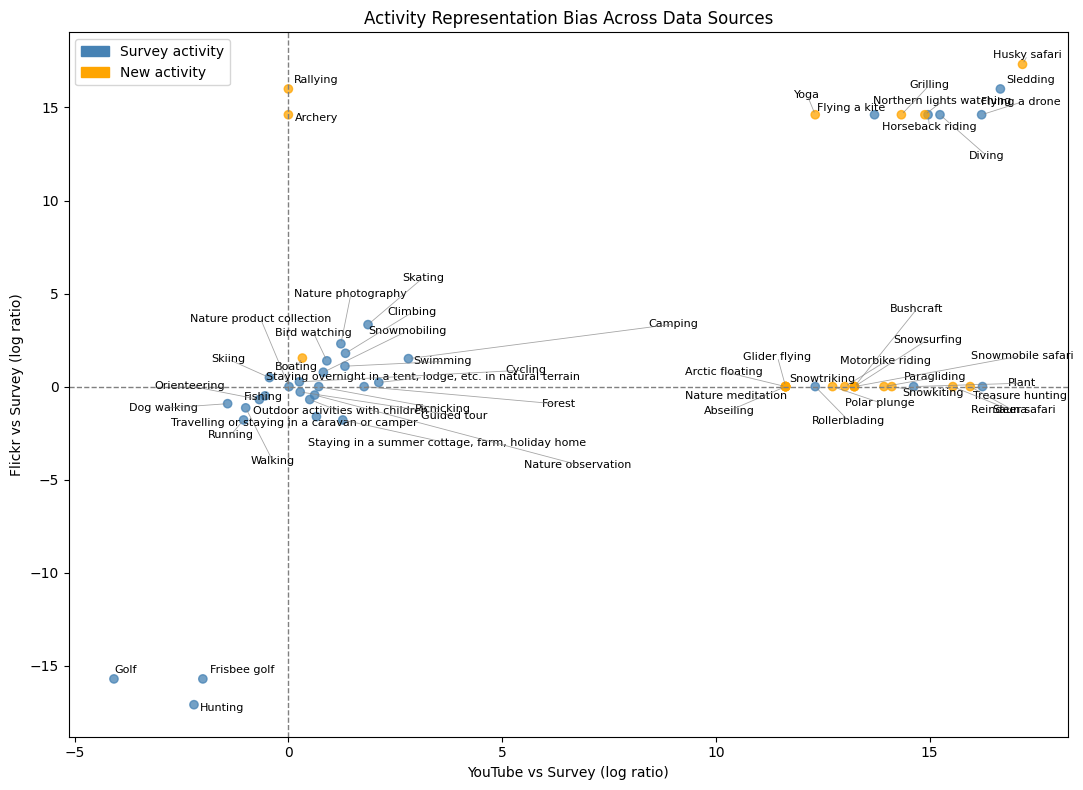

In [134]:
import matplotlib.pyplot as plt
from adjustText import adjust_text
# --- clean mapping (fix duplication) ---
activity_type_map = (
    df_all[["activity", "type"]]
    .drop_duplicates(subset=["activity"])
)

# --- merge safely ---
plot_df = pivot.reset_index().merge(
    activity_type_map,
    on="activity",
    how="left"
)

# color mapping
color_map = {
    "survey_activity": "steelblue",
    "new_activity": "orange"
}

plot_df["color"] = plot_df["type"].map(color_map).fillna("gray")

plt.figure(figsize=(11, 8))

# scatter
plt.scatter(
    plot_df["YouTube_vs_Survey"],
    plot_df["Flickr_vs_Survey"],
    c=plot_df["color"],
    alpha=0.75
)

# reference lines
plt.axhline(0, linestyle="--", linewidth=1, color="gray")
plt.axvline(0, linestyle="--", linewidth=1, color="gray")

# labels
texts = []
for _, row in plot_df.iterrows():
    texts.append(
        plt.text(
            row["YouTube_vs_Survey"],
            row["Flickr_vs_Survey"],
            row["activity"],
            fontsize=8
        )
    )

# adjust_text(
#     texts,
#     arrowprops=dict(arrowstyle="-", color="gray", lw=0.8)
# )
adjust_text(
    texts,

    # expand search space
    expand_points=(2, 2.5),
    expand_text=(2, 2.5),

    # stronger repulsion between labels
    force_points=(0.3, 0.5),
    force_text=(0.5, 0.8),

    # allow more movement
    lim=2000,

    # improve convergence
    precision=0.01,

    # allow arrows to help readability
    arrowprops=dict(
        arrowstyle="-",
        color="gray",
        lw=0.6,
        alpha=0.7
    )
)

# legend
plt.legend(handles=[
    mpatches.Patch(color="steelblue", label="Survey activity"),
    mpatches.Patch(color="orange", label="New activity"),
], loc="best")

plt.xlabel("YouTube vs Survey (log ratio)")
plt.ylabel("Flickr vs Survey (log ratio)")
plt.title("Activity Representation Bias Across Data Sources")

plt.tight_layout()
plt.show()

In [121]:
plot_df

,Flickr,LVVI3,YouTube,YouTube_vs_Survey,Flickr_vs_Survey,activity,type,color
1448,0.000000,0.000000,0.000112,11.630367,0.000000,Abseiling,new_activity,orange
9105,0.002212,0.000000,0.000000,0.000000,14.609584,Archery,new_activity,orange
2705,0.000000,0.000000,0.000112,11.630367,0.000000,Arctic floating,new_activity,orange
14,0.017699,0.004435,0.010909,0.900124,1.384079,Bird watching,survey_activity,steelblue
9375,0.017699,0.004435,0.010909,0.900124,1.384079,Bird watching,NaN,gray
...,...,...,...,...,...,...,...,...
95,0.000000,0.000000,0.011246,16.235529,0.000000,Treasure hunting,survey_activity,steelblue
229,0.000000,0.000000,0.011246,16.235529,0.000000,Treasure hunting,new_activity,orange
0,0.154867,0.485588,0.178925,-0.998394,-1.142791,Walking,survey_activity,steelblue
9441,0.154867,0.485588,0.178925,-0.998394,-1.142791,Walking,NaN,gray


# Determine anchor activities for trips

## Create trip x activity matrices

In [11]:
# Create YouTube matrix
youtube_matrix = (
    pd.crosstab(
        gdf_youtube["video_id"],
        gdf_youtube["activity"]
    )
    .clip(upper=1)
)

# Create Flickr matrix
flickr_matrix = (
    pd.crosstab(
        gdf_flickr["trip_id"],
        gdf_flickr["activity"]
    )
    .clip(upper=1)
)

# Combine matrix
youtube_matrix["source"] = "youtube"
flickr_matrix["source"] = "flickr"

trip_matrix = pd.concat(
    [youtube_matrix, flickr_matrix],
    axis=0
)

# Fill NaN
trip_matrix = trip_matrix.fillna(0)

## Method 1: Frequent itemset mining

In [12]:
from mlxtend.frequent_patterns import apriori

youtube_activities = youtube_matrix.select_dtypes(
    include=["int", "bool"]
)
freq_sets_youtube = apriori(
    youtube_activities,
    min_support=0.05,
    use_colnames=True
)

freq_sets_youtube.sort_values(
    "support",
    ascending=False
).head(30)

/projappl/project_2006782/leyixu/cv_env/lib64/python3.12/site-packages/mlxtend/frequent_patterns/fpcommon.py:175: DeprecationWarning: DataFrames with non-bool types result in worse computationalperformance and their support might be discontinued in the future.Please use a DataFrame with bool type
  warnings.warn(


,support,itemsets
13,0.398649,frozenset({Walking})
1,0.168399,frozenset({Camping})
12,0.156705,"frozenset({Staying overnight in a tent, lodge,..."
15,0.117464,"frozenset({Walking, Camping})"
9,0.116684,frozenset({Skiing})
14,0.110967,"frozenset({Staying overnight in a tent, lodge,..."
18,0.110967,"frozenset({Walking, Staying overnight in a ten..."
11,0.106809,"frozenset({Staying in a summer cottage, farm, ..."
6,0.104210,frozenset({Nature photography})
8,0.101091,frozenset({Picnicking})


In [11]:
from mlxtend.frequent_patterns import apriori

flickr_activities = flickr_matrix.select_dtypes(
    include=["int", "bool"]
)
freq_sets_flickr = apriori(
    flickr_activities,
    min_support=0.02,
    use_colnames=True
)

freq_sets_flickr.sort_values(
    "support",
    ascending=False
).head(30)

/projappl/project_2006782/leyixu/cv_env/lib64/python3.12/site-packages/mlxtend/frequent_patterns/fpcommon.py:175: DeprecationWarning: DataFrames with non-bool types result in worse computationalperformance and their support might be discontinued in the future.Please use a DataFrame with bool type
  warnings.warn(


,support,itemsets
12,0.191257,frozenset({Walking})
1,0.177596,frozenset({Boating})
10,0.177596,frozenset({Skiing})
7,0.163934,frozenset({Nature photography})
9,0.076503,frozenset({Skating})
3,0.060109,frozenset({Cycling})
6,0.040984,frozenset({Husky safari})
5,0.038251,frozenset({Fishing})
11,0.035519,frozenset({Snowmobiling})
8,0.030055,frozenset({Picnicking})


## Method 2: Associate rules

In [12]:
from mlxtend.frequent_patterns import association_rules

rules_youtube = association_rules(
    freq_sets_youtube,
    metric="confidence",
    min_threshold=0.5
)

rules_youtube

,antecedents,consequents,antecedent support,consequent support,support,confidence,lift,representativity,leverage,conviction,zhangs_metric,jaccard,certainty,kulczynski
0,frozenset({Camping}),"frozenset({Staying overnight in a tent, lodge,...",0.168399,0.156705,0.110967,0.658951,4.205045,1.0,0.084578,2.472648,0.916534,0.518204,0.595575,0.683538
1,"frozenset({Staying overnight in a tent, lodge,...",frozenset({Camping}),0.156705,0.168399,0.110967,0.708126,4.205045,1.0,0.084578,2.849178,0.903824,0.518204,0.649022,0.683538
2,frozenset({Camping}),frozenset({Walking}),0.168399,0.398649,0.117464,0.697531,1.749738,1.0,0.050332,1.988141,0.515254,0.261272,0.497018,0.496093
3,frozenset({Nature observation}),frozenset({Walking}),0.098233,0.398649,0.054054,0.550265,1.380325,1.0,0.014894,1.337122,0.305548,0.122066,0.252125,0.342929
4,frozenset({Picnicking}),frozenset({Walking}),0.101091,0.398649,0.071206,0.704370,1.766895,1.0,0.030906,2.034136,0.482847,0.166161,0.508391,0.441494
5,"frozenset({Staying overnight in a tent, lodge,...",frozenset({Walking}),0.156705,0.398649,0.110967,0.708126,1.776316,1.0,0.048497,2.060312,0.518249,0.249708,0.514637,0.493242
6,"frozenset({Walking, Camping})","frozenset({Staying overnight in a tent, lodge,...",0.117464,0.156705,0.084979,0.723451,4.616651,1.0,0.066572,3.049356,0.887661,0.449176,0.672062,0.632870
7,"frozenset({Staying overnight in a tent, lodge,...",frozenset({Walking}),0.110967,0.398649,0.084979,0.765808,1.921010,1.0,0.040742,2.567770,0.539283,0.200122,0.610557,0.489488
8,"frozenset({Walking, Staying overnight in a ten...",frozenset({Camping}),0.110967,0.168399,0.084979,0.765808,4.547576,1.0,0.066293,3.550936,0.877473,0.437166,0.718384,0.635219
9,frozenset({Camping}),"frozenset({Walking, Staying overnight in a ten...",0.168399,0.110967,0.084979,0.504630,4.547576,1.0,0.066293,1.794684,0.938073,0.437166,0.442799,0.635219


In [40]:
from mlxtend.frequent_patterns import association_rules

rules_flickr = association_rules(
    freq_sets_flickr,
    metric="confidence",
    min_threshold=0.1
)

rules_flickr

,antecedents,consequents,antecedent support,consequent support,support,confidence,lift,representativity,leverage,conviction,zhangs_metric,jaccard,certainty,kulczynski
0,frozenset({Nature photography}),frozenset({Walking}),0.163934,0.191257,0.021858,0.133333,0.697143,1.0,-0.009496,0.933165,-0.341935,0.065574,-0.071622,0.12381
1,frozenset({Walking}),frozenset({Nature photography}),0.191257,0.163934,0.021858,0.114286,0.697143,1.0,-0.009496,0.943945,-0.349451,0.065574,-0.059384,0.12381


## Method 3: Co-occurrence network

In [12]:
import networkx as nx

# Create activity matrix:
A_youtube = youtube_activities.values

# Create co-occurrence matrix
co_matrix_youtube = youtube_activities.T.dot(youtube_activities)

# Network
G_youtube = nx.from_pandas_adjacency(co_matrix_youtube)

# Centrality
centrality_youtube = nx.degree_centrality(G_youtube)

dict(sorted(centrality_youtube.items(), key=lambda item: item[1], reverse=True))

{'Camping': 0.8653846153846154,
 'Walking': 0.8653846153846154,
 'Staying in a summer cottage, farm, holiday home': 0.8076923076923077,
 'Nature observation': 0.7884615384615385,
 'Picnicking': 0.7884615384615385,
 'Staying overnight in a tent, lodge, etc. in natural terrain': 0.7884615384615385,
 'Nature photography': 0.7692307692307693,
 'Outdoor activities with children': 0.7692307692307693,
 'Cycling': 0.75,
 'Fishing': 0.75,
 'Travelling or staying in a caravan or camper': 0.75,
 'Nature product collection': 0.7307692307692308,
 'Sledding': 0.7307692307692308,
 'Boating': 0.7115384615384616,
 'Dog walking': 0.7115384615384616,
 'Guided tour': 0.7115384615384616,
 'Husky safari': 0.7115384615384616,
 'Skating': 0.7115384615384616,
 'Snowmobiling': 0.7115384615384616,
 'Swimming': 0.7115384615384616,
 'Forest': 0.6923076923076923,
 'Skiing': 0.6923076923076923,
 'Climbing': 0.6538461538461539,
 'Sauna': 0.6346153846153847,
 'Treasure hunting': 0.6346153846153847,
 'Bird watching': 0

In [13]:
# Create co-occurrence matrix
co_matrix_flickr = flickr_activities.T.dot(flickr_activities)

# Network
G_flickr = nx.from_pandas_adjacency(co_matrix_flickr)

# Centrality
centrality_flickr = nx.degree_centrality(G_flickr)

dict(sorted(centrality_flickr.items(), key=lambda item: item[1], reverse=True))


{'Nature photography': 0.5882352941176471,
 'Walking': 0.5588235294117647,
 'Nature observation': 0.4411764705882353,
 'Skiing': 0.4411764705882353,
 'Camping': 0.4117647058823529,
 'Climbing': 0.38235294117647056,
 'Skating': 0.38235294117647056,
 'Boating': 0.3235294117647059,
 'Bird watching': 0.2647058823529412,
 'Husky safari': 0.2647058823529412,
 'Northern lights watching': 0.2647058823529412,
 'Outdoor activities with children': 0.2647058823529412,
 'Swimming': 0.2647058823529412,
 'Cycling': 0.23529411764705882,
 'Staying overnight in a tent, lodge, etc. in natural terrain': 0.23529411764705882,
 'Picnicking': 0.20588235294117646,
 'Fishing': 0.1764705882352941,
 'Sledding': 0.1764705882352941,
 'Dog walking': 0.14705882352941177,
 'Snowmobiling': 0.14705882352941177,
 'Yoga': 0.14705882352941177,
 'Travelling or staying in a caravan or camper': 0.11764705882352941,
 'Archery': 0.08823529411764705,
 'Diving': 0.08823529411764705,
 'Grilling': 0.08823529411764705,
 'Guided tour

## Method 4: Community detection

In [14]:
from networkx.algorithms.community import greedy_modularity_communities

communities_youtube = greedy_modularity_communities(G_youtube)

communities_youtube

[frozenset({'Boating',
            'Diving',
            'Frisbee golf',
            'Golf',
            'Grilling',
            'Nature observation',
            'Nature product collection',
            'Outdoor activities with children',
            'Polar plunge',
            'Sauna',
            'Swimming',
            'Travelling or staying in a caravan or camper',
            'Walking'}),
 frozenset({'Bird watching',
            'Bushcraft',
            'Dog walking',
            'Flying a drone',
            'Forest',
            'Hunting',
            'Motorbike riding',
            'Nature photography',
            'Snowmobiling',
            'Staying overnight in a tent, lodge, etc. in natural terrain',
            'Treasure hunting',
            'Yoga'}),
 frozenset({'Fishing',
            'Guided tour',
            'Horseback riding',
            'Husky safari',
            'Northern lights watching',
            'Plant',
            'Reindeer safari',
            'Rollerbl

In [15]:
from networkx.algorithms.community import greedy_modularity_communities

communities_flickr = greedy_modularity_communities(G_flickr)

communities_flickr

[frozenset({'Camping',
            'Diving',
            'Husky safari',
            'Nature observation',
            'Nature photography',
            'Snowmobiling',
            'Staying overnight in a tent, lodge, etc. in natural terrain',
            'Swimming',
            'Travelling or staying in a caravan or camper'}),
 frozenset({'Archery',
            'Bird watching',
            'Nature product collection',
            'Picnicking',
            'Staying in a summer cottage, farm, holiday home',
            'Walking'}),
 frozenset({'Boating',
            'Climbing',
            'Fishing',
            'Guided tour',
            'Running',
            'Yoga'}),
 frozenset({'Dog walking', 'Grilling', 'Northern lights watching', 'Skating'}),
 frozenset({'Cycling',
            'Outdoor activities with children',
            'Skiing',
            'Sledding'}),
 frozenset({'Flying a drone'}),
 frozenset({'Flying a kite'}),
 frozenset({'Forest'}),
 frozenset({'Horseback riding'}),
 

In [34]:
gdf_youtube["activity_token"] = (
    gdf_youtube["activity"]
    .str.lower()
    .str.replace(" ", "_", regex=False)
)

gdf_flickr["activity_token"] = (
    gdf_flickr["activity"]
    .str.lower()
    .str.replace(" ", "_", regex=False)
)

# Identify trip types using Latent Class Analysis (LCA)

In [ ]:
# Get activities for postprocessing 
df_activities_post = pd.read_csv('../../data/LVVI3/LVVI3_activities_inference_postprocessing.csv')
df_activities_post

,structural_activity,activity,sub_activity,type
0,Adventure,Abseiling,Abseiling,new_activity
1,Adventure,Climbing,Climbing,survey_activity
2,Adventure,Climbing,Rock or mountain climbing,survey_activity
3,Adventure,Climbing,Ice climbing,new_activity
4,Adventure,Cycling,Cycling,survey_activity
...,...,...,...,...
120,Playful Exploration,Treasure hunting,Treasure hunting,survey_activity
121,Playful Exploration,Treasure hunting,Geocaching,survey_activity
122,Playful Exploration,Treasure hunting,Gold panning,new_activity
123,Adventure,Rallying,Rallying,new_activity


## LCA on structural activities in social media data

In [19]:
# Create trip x structural_activity matrix
lvvi3_lca = (
    pd.crosstab(
        df_lvvi3["kohdenro_reference_num"],
        df_lvvi3["structural_activity"]
    )
    .clip(upper=1)
)

youtube_lca = (
    pd.crosstab(
        gdf_youtube["video_id"],
        gdf_youtube["structural_activity"]
    )
    .clip(upper=1)
)

flickr_lca = (
    pd.crosstab(
        gdf_flickr["trip_id"],
        gdf_flickr["structural_activity"]
    )
    .clip(upper=1)
)

In [20]:
# Combine datasets
lvvi3_lca["source"] = "lvvi3"
youtube_lca["source"] = "youtube"
flickr_lca["source"] = "flickr"

trip_matrix = pd.concat(
    [lvvi3_lca, youtube_lca, flickr_lca],
    axis=0
).fillna(0)

# Save source
source = trip_matrix["source"]
trip_matrix = trip_matrix.drop(columns="source")

# Convert to integers
trip_matrix = trip_matrix.astype(int)

In [21]:
# Fit LCA models with different number of classes
from stepmix.stepmix import StepMix

results = []

for k in range(2, 11):

    model = StepMix(
        n_components=k,
        measurement="bernoulli",
        random_state=42
    )

    model.fit(trip_matrix)

    results.append({
        "n_classes": k,
        "bic": model.bic(trip_matrix),
        "aic": model.aic(trip_matrix)
    })

pd.DataFrame(results)

Fitting StepMix...


Initializations (n_init) : 100%|██████████| 1/1 [00:00<00:00,  2.80it/s, max_LL=-1.41e+4, max_avg_LL=-3.02]


Fitting StepMix...


Initializations (n_init) : 100%|██████████| 1/1 [00:00<00:00,  3.86it/s, max_LL=-1.37e+4, max_avg_LL=-2.94]


Fitting StepMix...


Initializations (n_init) : 100%|██████████| 1/1 [00:01<00:00,  1.47s/it, max_LL=-1.35e+4, max_avg_LL=-2.88]
/projappl/project_2006782/leyixu/cv_env/lib64/python3.12/site-packages/stepmix/stepmix.py:970: ConvergenceWarning: Initializations did not converge. Try different init parameters, or increase max_iter, abs_tol, rel_tol or check for degenerate data.
  warnings.warn(


Fitting StepMix...


Initializations (n_init) : 100%|██████████| 1/1 [00:01<00:00,  1.61s/it, max_LL=-1.33e+4, max_avg_LL=-2.85]
/projappl/project_2006782/leyixu/cv_env/lib64/python3.12/site-packages/stepmix/stepmix.py:970: ConvergenceWarning: Initializations did not converge. Try different init parameters, or increase max_iter, abs_tol, rel_tol or check for degenerate data.
  warnings.warn(


Fitting StepMix...


Initializations (n_init) : 100%|██████████| 1/1 [00:01<00:00,  1.07s/it, max_LL=-1.33e+4, max_avg_LL=-2.85]


Fitting StepMix...


Initializations (n_init) : 100%|██████████| 1/1 [00:01<00:00,  1.80s/it, max_LL=-1.32e+4, max_avg_LL=-2.82]
/projappl/project_2006782/leyixu/cv_env/lib64/python3.12/site-packages/stepmix/stepmix.py:970: ConvergenceWarning: Initializations did not converge. Try different init parameters, or increase max_iter, abs_tol, rel_tol or check for degenerate data.
  warnings.warn(


Fitting StepMix...


Initializations (n_init) : 100%|██████████| 1/1 [00:01<00:00,  1.92s/it, max_LL=-1.31e+4, max_avg_LL=-2.82]
/projappl/project_2006782/leyixu/cv_env/lib64/python3.12/site-packages/stepmix/stepmix.py:970: ConvergenceWarning: Initializations did not converge. Try different init parameters, or increase max_iter, abs_tol, rel_tol or check for degenerate data.
  warnings.warn(


Fitting StepMix...


Initializations (n_init) : 100%|██████████| 1/1 [00:01<00:00,  1.95s/it, max_LL=-1.31e+4, max_avg_LL=-2.81]
/projappl/project_2006782/leyixu/cv_env/lib64/python3.12/site-packages/stepmix/stepmix.py:970: ConvergenceWarning: Initializations did not converge. Try different init parameters, or increase max_iter, abs_tol, rel_tol or check for degenerate data.
  warnings.warn(


Fitting StepMix...


Initializations (n_init) : 100%|██████████| 1/1 [00:02<00:00,  2.02s/it, max_LL=-1.31e+4, max_avg_LL=-2.81]
/projappl/project_2006782/leyixu/cv_env/lib64/python3.12/site-packages/stepmix/stepmix.py:970: ConvergenceWarning: Initializations did not converge. Try different init parameters, or increase max_iter, abs_tol, rel_tol or check for degenerate data.
  warnings.warn(


,n_classes,bic,aic
0,2,28357.481442,28247.868109
1,3,27606.834586,27439.190665
2,4,27212.403384,26986.728875
3,5,26950.344688,26666.639591
4,6,27074.163270,26732.427585
5,7,26867.022823,26467.256550
6,8,26866.939828,26409.142967
7,9,26937.322380,26421.494931
8,10,27005.775133,26431.917096


<Axes: xlabel='n_classes'>

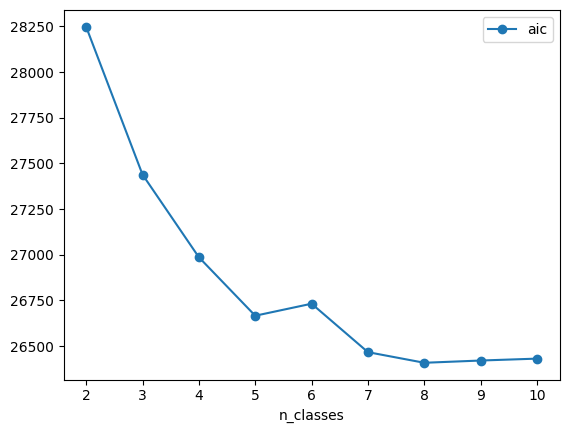

In [22]:
# Select number of trip types
results_df = pd.DataFrame(results)

results_df.plot(
    x="n_classes",
    y="aic",
    marker="o"
)

<Axes: xlabel='n_classes'>

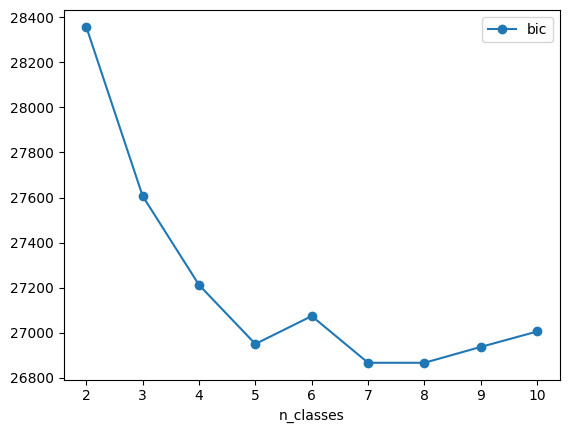

In [23]:
# Select number of trip types
results_df = pd.DataFrame(results)

results_df.plot(
    x="n_classes",
    y="bic",
    marker="o"
)

In [24]:
# Fit final model
lca = StepMix(
    n_components=5,
    measurement="bernoulli",
    random_state=42
)

lca.fit(trip_matrix)

Fitting StepMix...


Initializations (n_init) : 100%|██████████| 1/1 [00:01<00:00,  1.61s/it, max_LL=-1.33e+4, max_avg_LL=-2.85]
/projappl/project_2006782/leyixu/cv_env/lib64/python3.12/site-packages/stepmix/stepmix.py:970: ConvergenceWarning: Initializations did not converge. Try different init parameters, or increase max_iter, abs_tol, rel_tol or check for degenerate data.
  warnings.warn(


,n_components,5
,n_steps,1
,measurement,'bernoulli'
,structural,'gaussian_unit'
,assignment,'modal'
,correction,None
,abs_tol,1e-10
,rel_tol,0.0
,max_iter,1000
,n_init,1
,save_param_init,False


,n_components,5
,n_steps,1
,measurement,'bernoulli'
,structural,'gaussian_unit'
,assignment,'modal'
,correction,None
,abs_tol,1e-10
,rel_tol,0.0
,max_iter,1000
,n_init,1
,save_param_init,False


In [25]:
# Get trip membership probabilities
class_probs = lca.predict_proba(trip_matrix)

# Assign most likely type
trip_type = class_probs.argmax(axis=1)

trip_results = pd.DataFrame({
    "trip_type": trip_type
}, index=trip_matrix.index)

# Inspect classes
measurement = lca.get_mm_df()
measurement

class_no                                             0             1  \
model_name param variable                                              
binary     pis   Adventure                1.000000e+00  8.830787e-02   
                 Consumptive interaction  5.404136e-03  2.076911e-02   
                 Leisure                  2.020229e-04  1.000000e+00   
                 Nature Appreciation      1.270461e-02  4.196964e-02   
                 Nature Immersion         1.000000e-15  6.061989e-02   
                 Nature Management        6.741982e-04  8.546096e-04   
                 Organized Experience     1.000000e-15  1.000000e-15   
                 Playful Exploration      6.151055e-04  2.456411e-03   

class_no                                         2             3             4  
model_name param variable                                                       
binary     pis   Adventure                0.337549  1.000000e-15  2.371407e-01  
                 Consumptive interaction  0.158665  4.074705e-01  1.000000e-15  
                 Leisure                  0.682829  7.602036e-02  9.390698e-02  
                 Nature Appreciation      0.347636  5.455945e-01  4.133796e-02  
                 Nature Immersion         0.791412  1.000000e-15  1.000000e-15  
                 Nature Management        0.086665  1.031344e-02  2.403559e-03  
                 Organized Experience     0.099934  7.691502e-11  1.000000e+00  
                 Playful Exploration      0.026980  7.632220e-02  1.000000e-15

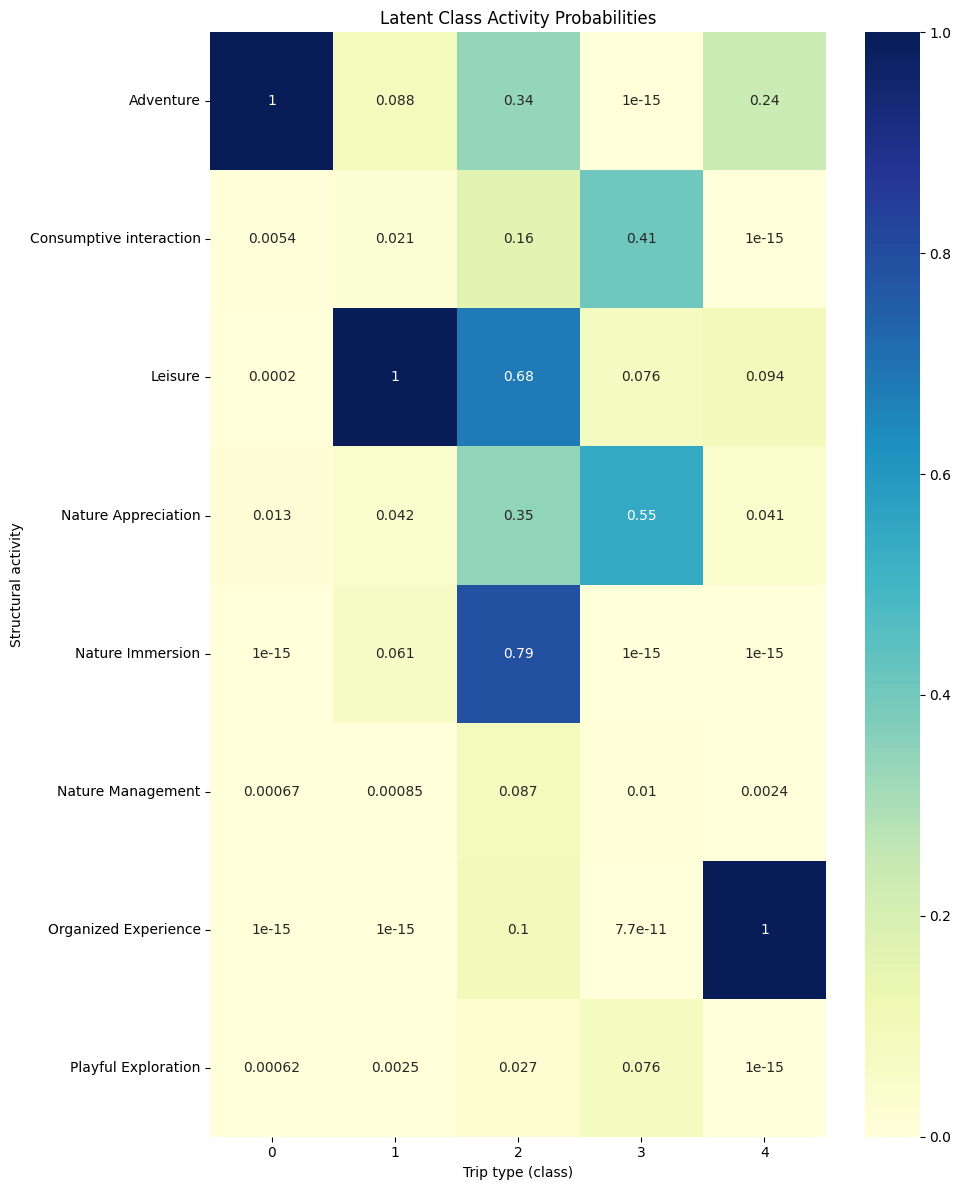

In [30]:
df = measurement.copy()

df = df.reset_index()

df_long = df.melt(
    id_vars=["variable"],
    value_vars=[0,1,2,3,4],
    var_name="class",
    value_name="probability"
)

import seaborn as sns
import matplotlib.pyplot as plt

heatmap_df = df_long.pivot(
    index="variable",
    columns="class",
    values="probability"
)

plt.figure(figsize=(10,12))

sns.heatmap(
    heatmap_df,
    annot=True,
    cmap="YlGnBu",
    vmin=0,
    vmax=1
)

plt.title("Latent Class Activity Probabilities")
plt.xlabel("Trip type (class)")
plt.ylabel("Structural activity")

plt.tight_layout()
plt.show()

In [31]:
df_long["rank"] = df_long.groupby("class")["probability"].rank(ascending=False)

df_long.sort_values(["class", "rank"]).head(20)

,variable,class,probability,rank
0,Adventure,0,1.000000e+00,1.0
3,Nature Appreciation,0,1.270461e-02,2.0
1,Consumptive interaction,0,5.404136e-03,3.0
5,Nature Management,0,6.741982e-04,4.0
7,Playful Exploration,0,6.151055e-04,5.0
2,Leisure,0,2.020229e-04,6.0
4,Nature Immersion,0,1.000000e-15,7.5
6,Organized Experience,0,1.000000e-15,7.5
10,Leisure,1,1.000000e+00,1.0
8,Adventure,1,8.830787e-02,2.0


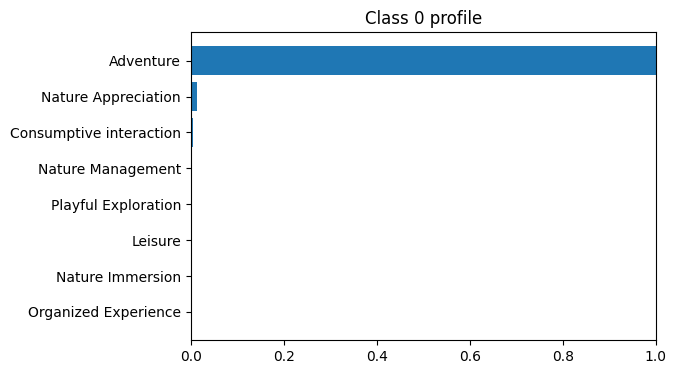

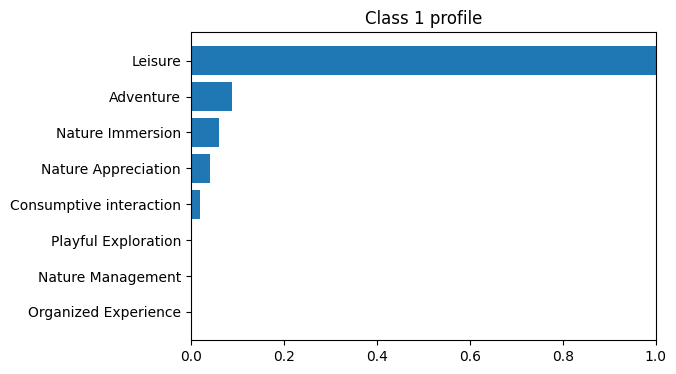

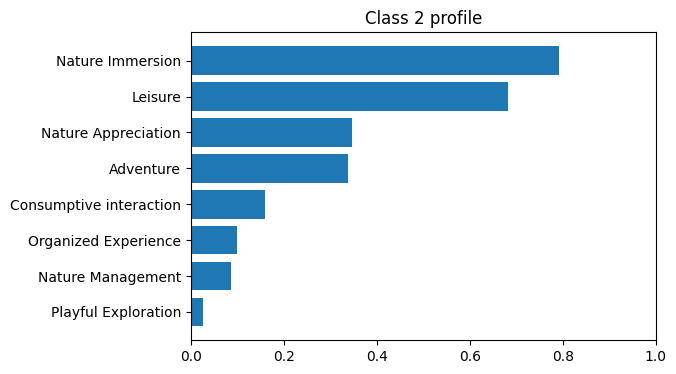

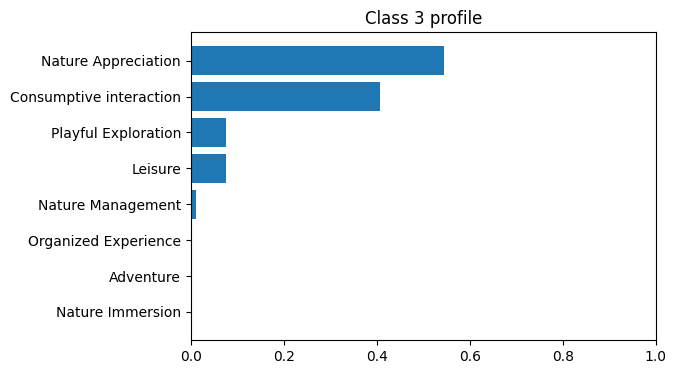

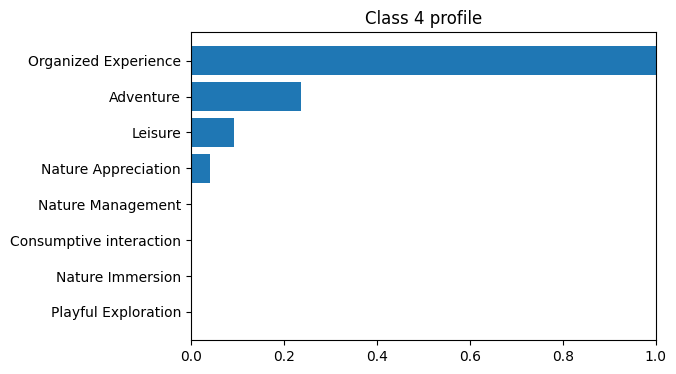

In [32]:
top_k = 8

for c in sorted(df_long["class"].unique()):

    tmp = df_long[df_long["class"] == c]

    tmp = tmp.sort_values("probability", ascending=False).head(top_k)

    plt.figure(figsize=(6,4))

    plt.barh(tmp["variable"], tmp["probability"])

    plt.gca().invert_yaxis()

    plt.title(f"Class {c} profile")

    plt.xlim(0,1)

    plt.show()

In [29]:
# Characterize trip types
gdf_trips = (
    trip_results
    .reset_index()
)

# Merge trip types back
df_lvvi3_triptypes = (
    df_lvvi3
    .merge(
        gdf_trips,
        left_on="kohdenro_reference_num",
        right_on="index",
        how="left"
    )
)

gdf_youtube_triptypes = (
    gdf_youtube
    .merge(
        gdf_trips,
        left_on="video_id",
        right_on="index",
        how="left"
    )
)

gdf_flickr_triptypes = (
    gdf_flickr
    .merge(
        gdf_trips,
        left_on="trip_id",
        right_on="index",
        how="left"
    )
)

In [34]:
gdf_trips.trip_type.value_counts()

trip_type
1    1609
2    1294
0    1017
3     487
4     258
Name: count, dtype: int64

## LCA on activities in social media data

In [26]:
# Create trip x activity matrix
youtube_lca = (
    pd.crosstab(
        gdf_youtube["video_id"],
        gdf_youtube["activity"]
    )
    .clip(upper=1)
)

flickr_lca = (
    pd.crosstab(
        gdf_flickr["trip_id"],
        gdf_flickr["activity"]
    )
    .clip(upper=1)
)

In [27]:
# Combine datasets
youtube_lca["source"] = "youtube"
flickr_lca["source"] = "flickr"

trip_matrix = pd.concat(
    [youtube_lca, flickr_lca],
    axis=0
).fillna(0)

# Save source
source = trip_matrix["source"]
trip_matrix = trip_matrix.drop(columns="source")

# Convert to integers
trip_matrix = trip_matrix.astype(int)

In [49]:
# Fit LCA models with different number of classes
from stepmix.stepmix import StepMix

results = []

for k in range(2, 11):

    model = StepMix(
        n_components=k,
        measurement="bernoulli",
        random_state=42
    )

    model.fit(trip_matrix)

    results.append({
        "n_classes": k,
        "bic": model.bic(trip_matrix),
        "aic": model.aic(trip_matrix)
    })

pd.DataFrame(results)

Fitting StepMix...


Initializations (n_init) : 100%|██████████| 1/1 [00:00<00:00,  3.32it/s, max_LL=-2.73e+4, max_avg_LL=-6.48]


Fitting StepMix...


Initializations (n_init) : 100%|██████████| 1/1 [00:00<00:00,  1.19it/s, max_LL=-2.68e+4, max_avg_LL=-6.36]


Fitting StepMix...


Initializations (n_init) : 100%|██████████| 1/1 [00:00<00:00,  1.13it/s, max_LL=-2.64e+4, max_avg_LL=-6.27]


Fitting StepMix...


Initializations (n_init) : 100%|██████████| 1/1 [00:00<00:00,  1.49it/s, max_LL=-2.63e+4, max_avg_LL=-6.23]


Fitting StepMix...


Initializations (n_init) : 100%|██████████| 1/1 [00:02<00:00,  2.81s/it, max_LL=-2.61e+4, max_avg_LL=-6.2]
/projappl/project_2006782/leyixu/cv_env/lib64/python3.12/site-packages/stepmix/stepmix.py:970: ConvergenceWarning: Initializations did not converge. Try different init parameters, or increase max_iter, abs_tol, rel_tol or check for degenerate data.
  warnings.warn(


Fitting StepMix...


Initializations (n_init) : 100%|██████████| 1/1 [00:00<00:00,  1.43it/s, max_LL=-2.6e+4, max_avg_LL=-6.16]


Fitting StepMix...


Initializations (n_init) : 100%|██████████| 1/1 [00:01<00:00,  1.99s/it, max_LL=-2.56e+4, max_avg_LL=-6.08]


Fitting StepMix...


Initializations (n_init) : 100%|██████████| 1/1 [00:02<00:00,  2.98s/it, max_LL=-2.55e+4, max_avg_LL=-6.05]
/projappl/project_2006782/leyixu/cv_env/lib64/python3.12/site-packages/stepmix/stepmix.py:970: ConvergenceWarning: Initializations did not converge. Try different init parameters, or increase max_iter, abs_tol, rel_tol or check for degenerate data.
  warnings.warn(


Fitting StepMix...


Initializations (n_init) : 100%|██████████| 1/1 [00:02<00:00,  2.48s/it, max_LL=-2.55e+4, max_avg_LL=-6.04]


,n_classes,bic,aic
0,2,55579.094380,54874.669777
1,3,54978.519195,53918.709207
2,4,54732.152489,53316.957116
3,5,54845.870727,53075.289968
4,6,55024.642844,52898.676700
5,7,55191.771967,52710.420437
6,8,54987.499550,52150.762635
7,9,55159.506388,51967.384088
8,10,55608.221687,52060.714002


<Axes: xlabel='n_classes'>

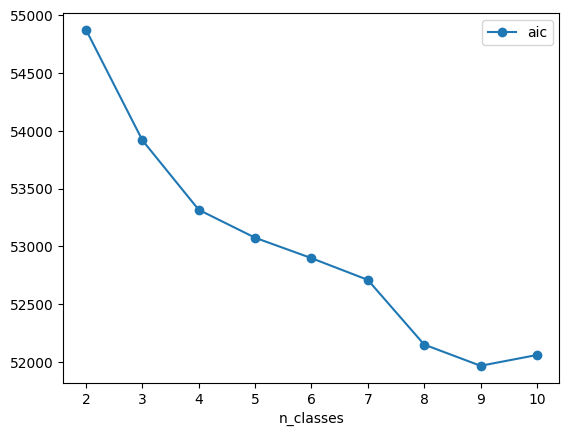

In [50]:
# Select number of trip types
results_df = pd.DataFrame(results)

results_df.plot(
    x="n_classes",
    y="aic",
    marker="o"
)

<Axes: xlabel='n_classes'>

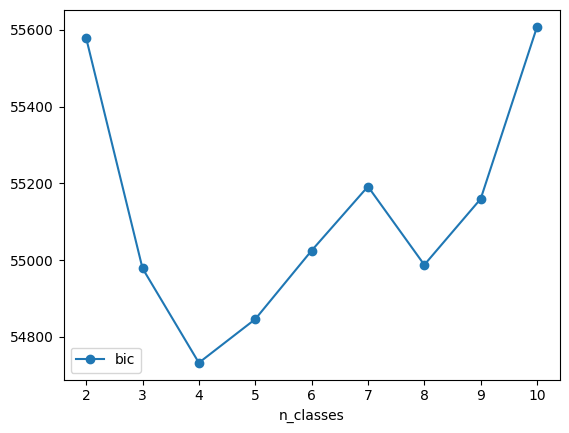

In [51]:
# Select number of trip types
results_df = pd.DataFrame(results)

results_df.plot(
    x="n_classes",
    y="bic",
    marker="o"
)

In [87]:
# Fit final model
lca = StepMix(
    n_components=4,
    measurement="bernoulli",
    random_state=42
)

lca.fit(trip_matrix)

Fitting StepMix...


Initializations (n_init) :   0%|          | 0/1 [00:00<?, ?it/s]

Initializations (n_init) : 100%|██████████| 1/1 [00:01<00:00,  1.04s/it, max_LL=-2.64e+4, max_avg_LL=-6.27]


,n_components,4
,n_steps,1
,measurement,'bernoulli'
,structural,'gaussian_unit'
,assignment,'modal'
,correction,None
,abs_tol,1e-10
,rel_tol,0.0
,max_iter,1000
,n_init,1
,save_param_init,False


In [88]:
# Get trip membership probabilities
class_probs = lca.predict_proba(trip_matrix)

# Assign most likely type
trip_type = class_probs.argmax(axis=1)

trip_results = pd.DataFrame({
    "trip_type": trip_type
}, index=trip_matrix.index)

# Inspect classes
measurement = lca.get_mm_df()
measurement

class_no                                                                        0  \
model_name param variable                                                           
binary     pis   Abseiling                                           1.000000e-15   
                 Archery                                             1.000000e-15   
                 Arctic floating                                     4.294977e-04   
                 Bird watching                                       1.430033e-02   
                 Boating                                             9.459186e-02   
                 Bushcraft                                           1.000000e-15   
                 Camping                                             2.700891e-02   
                 Climbing                                            1.315689e-02   
                 Cycling                                             1.251686e-01   
                 Diving                                              1.193944e-02   
                 Dog walking                                         1.599502e-02   
                 Fishing                                             6.402219e-02   
                 Flying a drone                                      2.854858e-02   
                 Flying a kite                                       3.865479e-03   
                 Forest                                              5.513682e-03   
                 Frisbee golf                                        2.142817e-03   
                 Glider flying                                       4.294977e-04   
                 Golf                                                1.000000e-15   
                 Grilling                                            4.127268e-04   
                 Guided tour                                         1.880464e-02   
                 Horseback riding                                    6.697372e-03   
                 Hunting                                             6.409120e-03   
                 Husky safari                                        7.953667e-02   
                 Motorbike riding                                    8.588157e-04   
                 Nature meditation                                   4.294977e-04   
                 Nature observation                                  3.466906e-02   
                 Nature photography                                  1.025997e-01   
                 Nature product collection                           1.113336e-02   
                 Northern lights watching                            5.121977e-05   
                 Orienteering                                        6.493510e-03   
                 Outdoor activities with children                    3.809942e-02   
                 Paragliding                                         2.984762e-03   
                 Picnicking                                          2.139027e-02   
                 Plant                                               2.093393e-03   
                 Polar plunge                                        4.294978e-04   
                 Rallying                                            1.717991e-03   
                 Reindeer safari                                     1.218226e-02   
                 Rollerblading                                       8.589954e-04   
                 Running                                             2.425287e-02   
                 Sauna                                               2.002267e-03   
                 Skating                                             4.370516e-02   
                 Skiing                                              1.633900e-01   
                 Sledding                                            4.000672e-02   
                 Snowkiting                                          3.006484e-03   
                 Snowmobile safari                                   8.589954e-04   
     

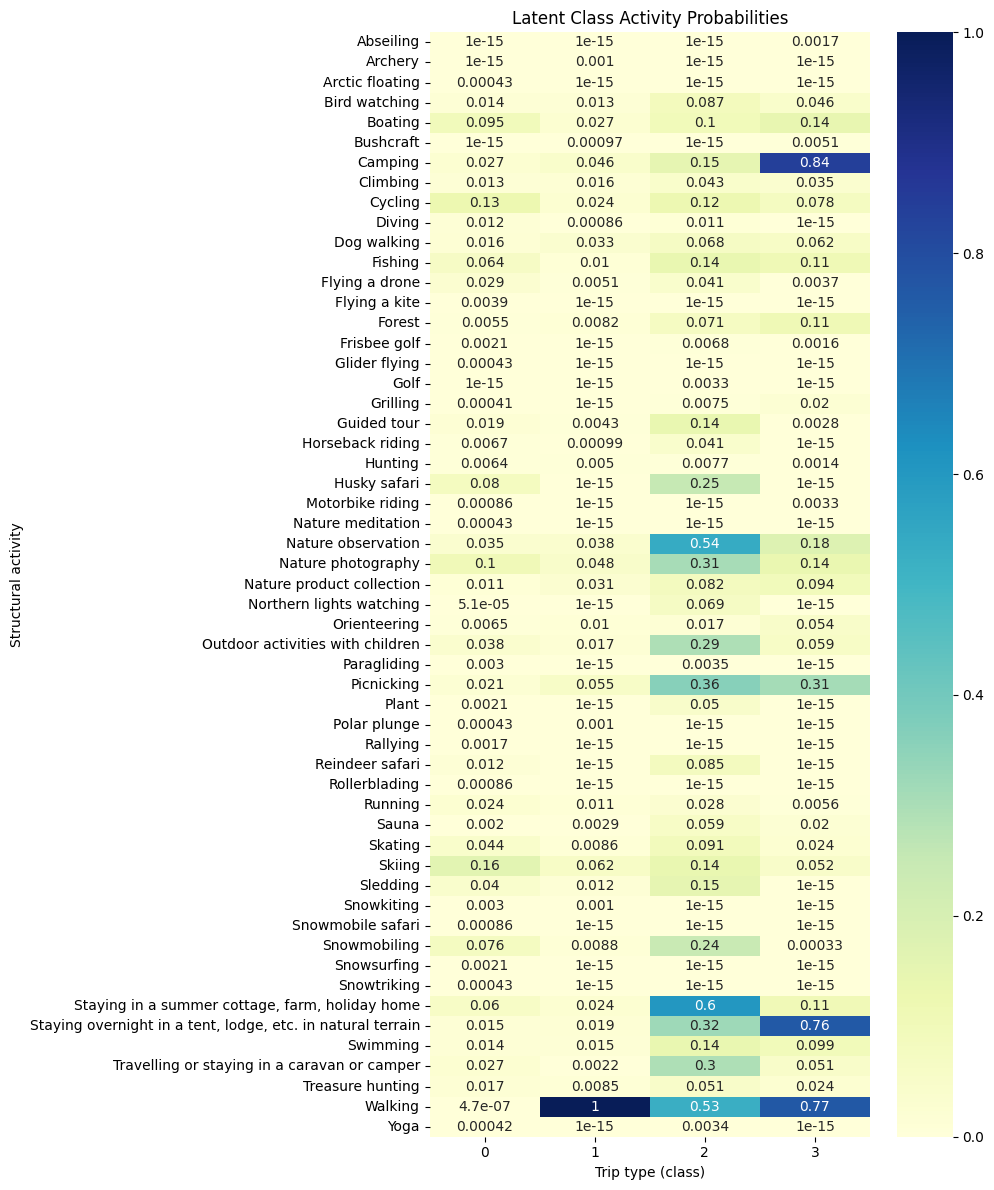

In [89]:
df = measurement.copy()

df = df.reset_index()

df_long = df.melt(
    id_vars=["variable"],
    value_vars=[0,1,2,3],
    var_name="class",
    value_name="probability"
)

import seaborn as sns
import matplotlib.pyplot as plt

heatmap_df = df_long.pivot(
    index="variable",
    columns="class",
    values="probability"
)

plt.figure(figsize=(10,12))

sns.heatmap(
    heatmap_df,
    annot=True,
    cmap="YlGnBu",
    vmin=0,
    vmax=1
)

plt.title("Latent Class Activity Probabilities")
plt.xlabel("Trip type (class)")
plt.ylabel("Structural activity")

plt.tight_layout()
plt.show()

In [90]:
df_long["rank"] = df_long.groupby("class")["probability"].rank(ascending=False)

df_long.sort_values(["class", "rank"]).head(20)

,variable,class,probability,rank
41,Skiing,0,0.163390,1.0
8,Cycling,0,0.125169,2.0
26,Nature photography,0,0.102600,3.0
4,Boating,0,0.094592,4.0
22,Husky safari,0,0.079537,5.0
45,Snowmobiling,0,0.075998,6.0
11,Fishing,0,0.064022,7.0
48,"Staying in a summer cottage, farm, holiday home",0,0.060395,8.0
40,Skating,0,0.043705,9.0
42,Sledding,0,0.040007,10.0


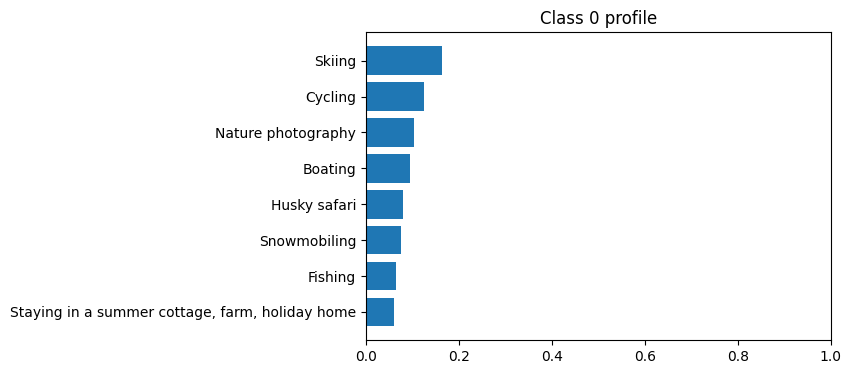

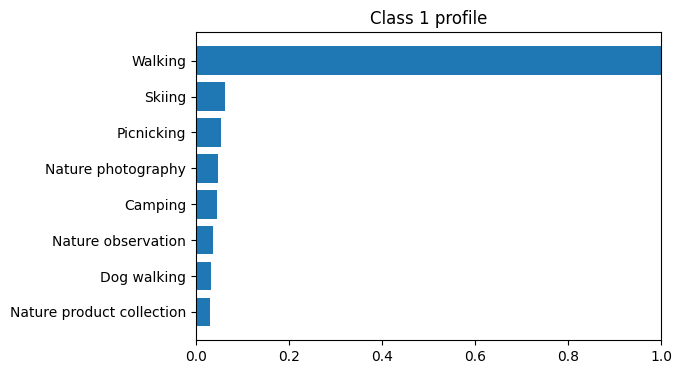

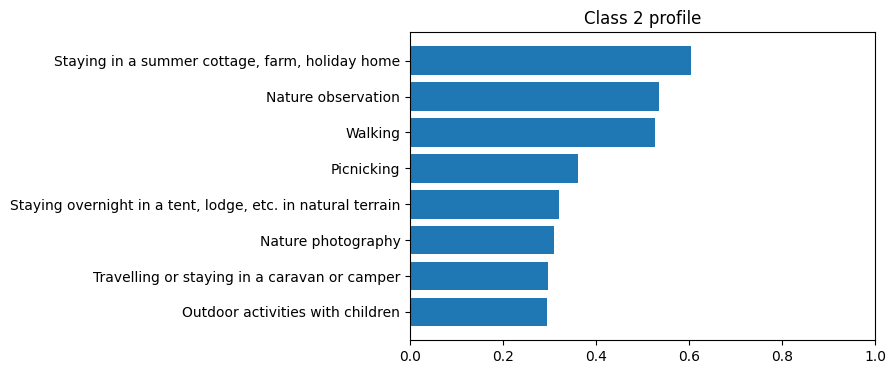

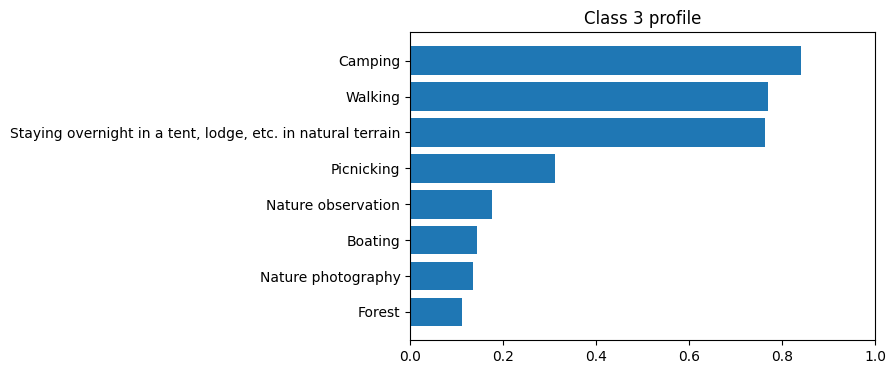

In [91]:
top_k = 8

for c in sorted(df_long["class"].unique()):

    tmp = df_long[df_long["class"] == c]

    tmp = tmp.sort_values("probability", ascending=False).head(top_k)

    plt.figure(figsize=(6,4))

    plt.barh(tmp["variable"], tmp["probability"])

    plt.gca().invert_yaxis()

    plt.title(f"Class {c} profile")

    plt.xlim(0,1)

    plt.show()

In [27]:
# Characterize trip types
gdf_trips = (
    trip_results
    .reset_index()
)

# Merge trip types back
gdf_youtube_triptypes = (
    gdf_youtube
    .merge(
        gdf_trips,
        left_on="video_id",
        right_on="index",
        how="left"
    )
)

gdf_flickr_triptypes = (
    gdf_flickr
    .merge(
        gdf_trips,
        left_on="trip_id",
        right_on="index",
        how="left"
    )
)

In [95]:
gdf_trips.trip_type.value_counts()

trip_type
0    2370
1    1017
3     555
2     272
Name: count, dtype: int64

## Assign classes to LVVI3 trips based on activities

In [96]:
lca_probs = measurement.copy()

lca_probs = (
    lca_probs
    .reset_index()
    .rename(columns={"variable": "activity"})
)

lca_probs.head()

class_cols = lca_probs.columns[
    lca_probs.columns.map(lambda x: isinstance(x, int))
].tolist()

class_cols

[0, 1, 2, 3]

In [97]:
class_prior = (
    lca_probs[class_cols]
    .sum(axis=0)
)

class_prior = class_prior / class_prior.sum()

class_prior

class_no
0    0.097432
1    0.122988
2    0.449672
3    0.329908
dtype: float64

In [98]:
bayes_probs = lca_probs.copy()

for c in class_cols:
    bayes_probs[c] = (
        bayes_probs[c]
        * class_prior[c]
    )

In [99]:
bayes_probs[class_cols] = (
    bayes_probs[class_cols]
    .div(
        bayes_probs[class_cols].sum(axis=1),
        axis=0
    )
)

In [100]:
lvvi3_prob = df_lvvi3.merge(
    bayes_probs[
        ["activity"] + class_cols
    ],
    on="activity",
    how="left"
)

In [101]:
lvvi3_prob["max_prob"] = (
    lvvi3_prob[class_cols]
    .max(axis=1)
)

In [102]:
import numpy as np

lvvi3_prob["entropy"] = -(
    lvvi3_prob[class_cols]
    * np.log(
        lvvi3_prob[class_cols] + 1e-12
    )
).sum(axis=1)

In [103]:
lvvi3_prob["trip_type"] = (
    lvvi3_prob[class_cols]
    .idxmax(axis=1)
)

In [104]:
lvvi3_prob["max_prob"].describe()

count    451.000000
mean       0.533592
std        0.147376
min        0.413705
25%        0.413705
50%        0.453745
75%        0.605590
max        1.000000
Name: max_prob, dtype: float64

In [105]:
lvvi3_prob["entropy"].describe()

count    4.510000e+02
mean     9.569697e-01
std      1.945693e-01
min      9.517407e-12
25%      9.423276e-01
50%      1.054863e+00
75%      1.054863e+00
max      1.082552e+00
Name: entropy, dtype: float64

In [106]:
lvvi3_prob["match_quality"] = np.where(
    lvvi3_prob["max_prob"] < 0.4,
    "Poor match",
    "Good match"
)

entropy_threshold = (
    lvvi3_prob["entropy"]
    .quantile(0.90)
)

lvvi3_prob["match_quality"] = np.where(
    lvvi3_prob["entropy"] > entropy_threshold,
    "Poor match",
    "Good match"
)

In [107]:
(
    lvvi3_prob["match_quality"]
    .value_counts(normalize=True)
    .round(3)
)

match_quality
Good match    0.911
Poor match    0.089
Name: proportion, dtype: float64

In [108]:
poor_match = lvvi3_prob[
    lvvi3_prob["match_quality"] == "Poor match"
]

poor_match["activity"].value_counts().head(20)

activity
Skiing    40
Name: count, dtype: int64

In [109]:
comparison = pd.concat([
    (
        df_lvvi3["activity"]
        .value_counts(normalize=True)
        .rename("All trips")
    ),
    (
        poor_match["activity"]
        .value_counts(normalize=True)
        .rename("Poor matches")
    )
], axis=1).fillna(0)

comparison

,All trips,Poor matches
activity,,
Walking,0.485588,0.0
Skiing,0.088692,1.0
Dog walking,0.055432,0.0
Fishing,0.050998,0.0
Cycling,0.037694,0.0
Boating,0.031042,0.0
Hunting,0.026608,0.0
Running,0.026608,0.0
Nature observation,0.024390,0.0


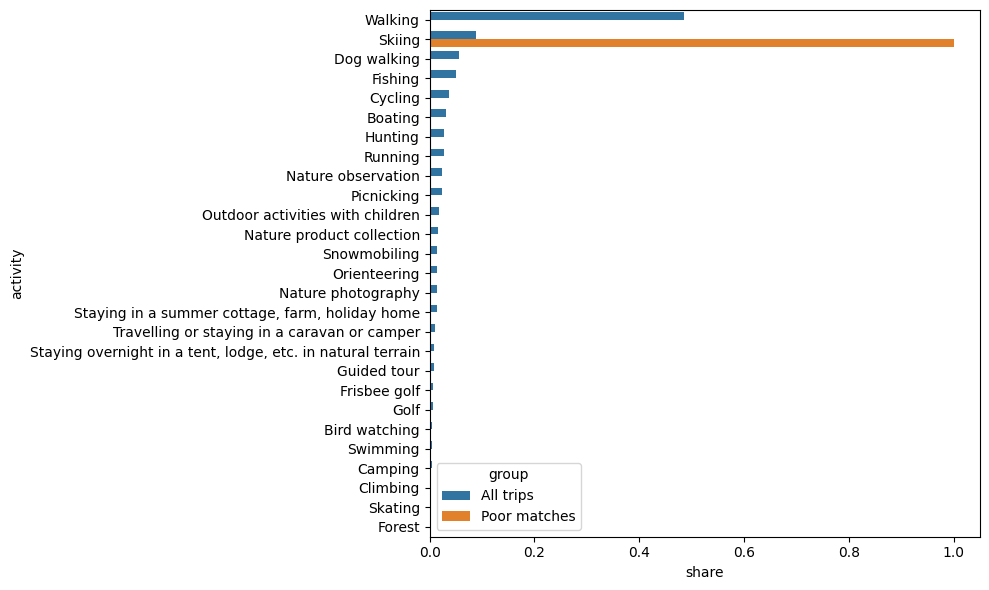

In [110]:
import seaborn as sns
import matplotlib.pyplot as plt

comparison = (
    comparison
    .reset_index()
    .rename(columns={"index":"activity"})
)

comparison_long = comparison.melt(
    id_vars="activity",
    var_name="group",
    value_name="share"
)

plt.figure(figsize=(10,6))

sns.barplot(
    data=comparison_long,
    x="share",
    y="activity",
    hue="group"
)

plt.tight_layout()
plt.show()

<Axes: xlabel='trip_type', ylabel='max_prob'>

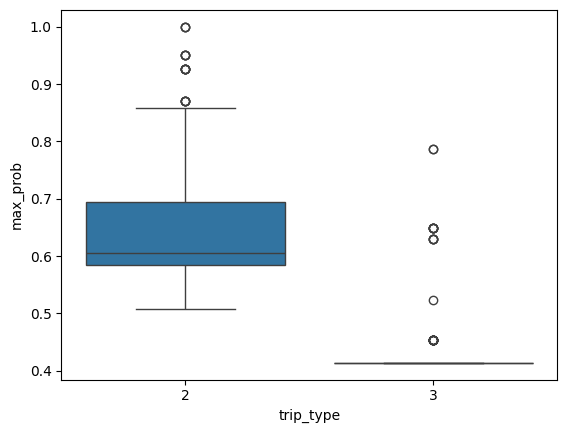

In [111]:
sns.boxplot(
    data=lvvi3_prob,
    x="trip_type",
    y="max_prob"
)

In [113]:
class_cols = [c for c in lvvi3_prob.columns if isinstance(c, int)]

lvvi3_prob["trip_type"] = lvvi3_prob[class_cols].idxmax(axis=1)

lvvi3_prob["trip_type_prob"] = lvvi3_prob[class_cols].max(axis=1)

df_lvvi3_triptypes = lvvi3_prob.drop(columns=class_cols)

# df_lvvi3_triptypes = df_lvvi3_triptypes[[
#     "trip_id",
#     "activity",              # original survey activity
#     "structural_activity",
#     "trip_type",
#     "trip_type_prob",
#     "max_prob",
#     "entropy"
# ]]

df_lvvi3_triptypes["match_quality"] = (
    df_lvvi3_triptypes["max_prob"]
    .apply(lambda x: "low_confidence" if x < 0.4 else "high_confidence")
)

df_lvvi3_triptypes

,kohdenro_reference_num,paino2_weight,A1_gender,A2_age,A48_last_activity_time,TA49h_last_activity_duration,A50_travel_time,A51_km_travel_distance,A_paiva1_day_trip_last_year,A_paiva2_day_trip_last_year_times,...,gender,age_group,structural_activity,accompany,social_composition,max_prob,entropy,trip_type,match_quality,trip_type_prob
0,11885,564.251390,1,5,2.0,6.00,6.0,320.0,2.0,20.0,...,Male,45-54,Adventure,With friends,With group,0.926962,2.939284e-01,2,high_confidence,0.926962
1,30988,432.243936,1,7,2.0,4.00,2.0,1.0,1.0,NaN,...,Male,65-74,Adventure,With friends,With group,0.926962,2.939284e-01,2,high_confidence,0.926962
2,31908,594.559221,1,3,2.0,1.50,2.0,3.0,1.0,NaN,...,Male,25-34,Adventure,Alone,Alone,0.926962,2.939284e-01,2,high_confidence,0.926962
3,10076,595.644327,1,3,10.0,3.00,6.0,72.0,1.0,NaN,...,Male,25-34,Leisure,With friends,With group,0.805505,6.085504e-01,2,high_confidence,0.805505
4,31734,387.434733,2,6,2.0,2.00,2.0,1.0,3.0,NaN,...,Female,55-64,Leisure,With friends,With group,1.000000,9.517407e-12,2,high_confidence,1.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
446,54518,468.000935,2,5,1.0,0.75,2.0,0.1,NaN,NaN,...,Female,45-54,Leisure,With family,With group,0.413705,1.054863e+00,3,high_confidence,0.413705
447,54590,564.251390,1,5,2.0,1.00,1.0,3.0,NaN,NaN,...,Male,45-54,Leisure,With friends,With group,0.413705,1.054863e+00,3,high_confidence,0.413705
448,54607,467.115705,1,6,9.0,4.00,4.0,25.0,NaN,NaN,...,Male,55-64,Leisure,With family,With group,0.413705,1.054863e+00,3,high_confidence,0.413705
449,54801,467.115705,1,6,9.0,5.00,5.0,30.0,NaN,NaN,...,Male,55-64,Leisure,With family,With group,0.413705,1.054863e+00,3,high_confidence,0.413705


# Explore trip type characteristics

In [31]:
# Create trip-level dataset
youtube_trip_demo = (
    gdf_youtube_triptypes[
        ["video_id", "trip_type", "social_composition", "commercial_forest"]
    ]
    .drop_duplicates(subset=["video_id"])
)

flickr_trip_demo = (
    gdf_flickr_triptypes[
        ["trip_id", "trip_type", "age_group", "gender", "social_composition", "commercial_forest"]
    ]
    .drop_duplicates(subset=["trip_id"])
)

lvvi3_trip_demo = (
    df_lvvi3_triptypes[
        ["kohdenro_reference_num", "trip_type", "age_group", "gender", "social_composition"]
    ]
    .drop_duplicates(subset=["kohdenro_reference_num"])
)

## Activity

In [32]:
gdf_youtube_triptypes["source"] = "YouTube"
gdf_flickr_triptypes["source"] = "Flickr"
df_lvvi3_triptypes["source"] = "LVVI3"

df_all = pd.concat([
    gdf_youtube_triptypes,
    gdf_flickr_triptypes,
    df_lvvi3_triptypes
], ignore_index=True)

In [33]:
activity_profile = (
    df_all
    .groupby(["trip_type", "activity"])
    .size()
    .reset_index(name="count")
)

activity_profile["share"] = (
    activity_profile
    .groupby("trip_type")["count"]
    .transform(lambda x: x / x.sum())
)

In [50]:
top_activities = (
    activity_profile
    .sort_values(["trip_type", "share"], ascending=[True, False])
    .groupby("trip_type")
    .head(10)
)

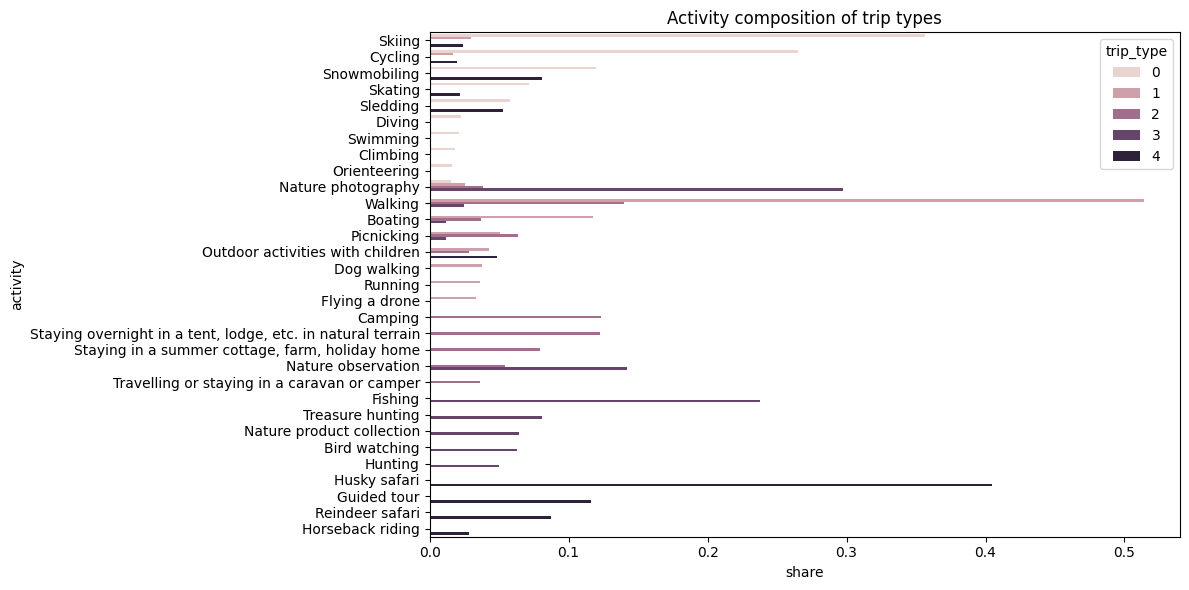

In [51]:
plt.figure(figsize=(12,6))

sns.barplot(
    data=top_activities,
    x="share",
    y="activity",
    hue="trip_type"
)

plt.title("Activity composition of trip types")
plt.tight_layout()
plt.show()

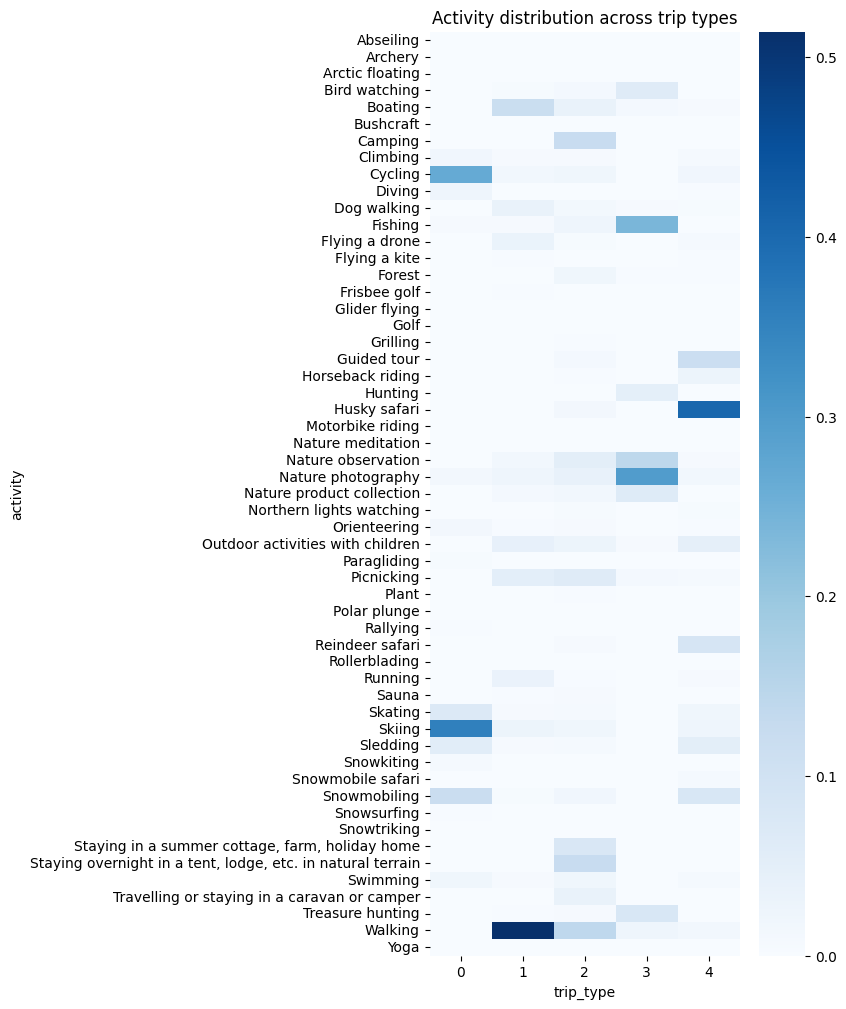

In [52]:
heatmap_df = activity_profile.pivot(
    index="activity",
    columns="trip_type",
    values="share"
).fillna(0)

plt.figure(figsize=(5,12))

sns.heatmap(
    heatmap_df,
    # annot=True,
    cmap="Blues"
)

plt.title("Activity distribution across trip types")
plt.show()

In [53]:
struct_profile

,trip_type,structural_activity,count,share
0,0,Adventure,1154,0.972199
1,0,Consumptive interaction,10,0.008425
2,0,Nature Appreciation,22,0.018534
3,0,Playful Exploration,1,0.000842
4,1,Adventure,181,0.084461
5,1,Consumptive interaction,43,0.020065
6,1,Leisure,1810,0.844610
7,1,Nature Appreciation,102,0.047597
8,1,Playful Exploration,7,0.003266
9,2,Adventure,633,0.117157


In [54]:
activity_profile

,trip_type,activity,count,share
0,0,Bird watching,2,0.001685
1,0,Climbing,22,0.018534
2,0,Cycling,315,0.265375
3,0,Diving,27,0.022746
4,0,Fishing,8,0.006740
...,...,...,...,...
140,4,Sledding,24,0.052516
141,4,Snowmobile safari,4,0.008753
142,4,Snowmobiling,37,0.080963
143,4,Swimming,4,0.008753


In [55]:
# Renders the full dataframe in an internal scrollable HTML box
activity_profile.to_html()

# Or wrap it in a scrollable HTML div for better UI control:
from IPython.display import display, HTML
display(HTML(f"<div style='max-height: 500px; overflow-y: auto;'>{activity_profile.to_html()}</div>"))

,trip_type,activity,count,share
0,0,Bird watching,2,0.001685
1,0,Climbing,22,0.018534
2,0,Cycling,315,0.265375
3,0,Diving,27,0.022746
4,0,Fishing,8,0.006740
5,0,Glider flying,1,0.000842
6,0,Hunting,1,0.000842
7,0,Motorbike riding,1,0.000842
8,0,Nature observation,2,0.001685
9,0,Nature photography,18,0.015164


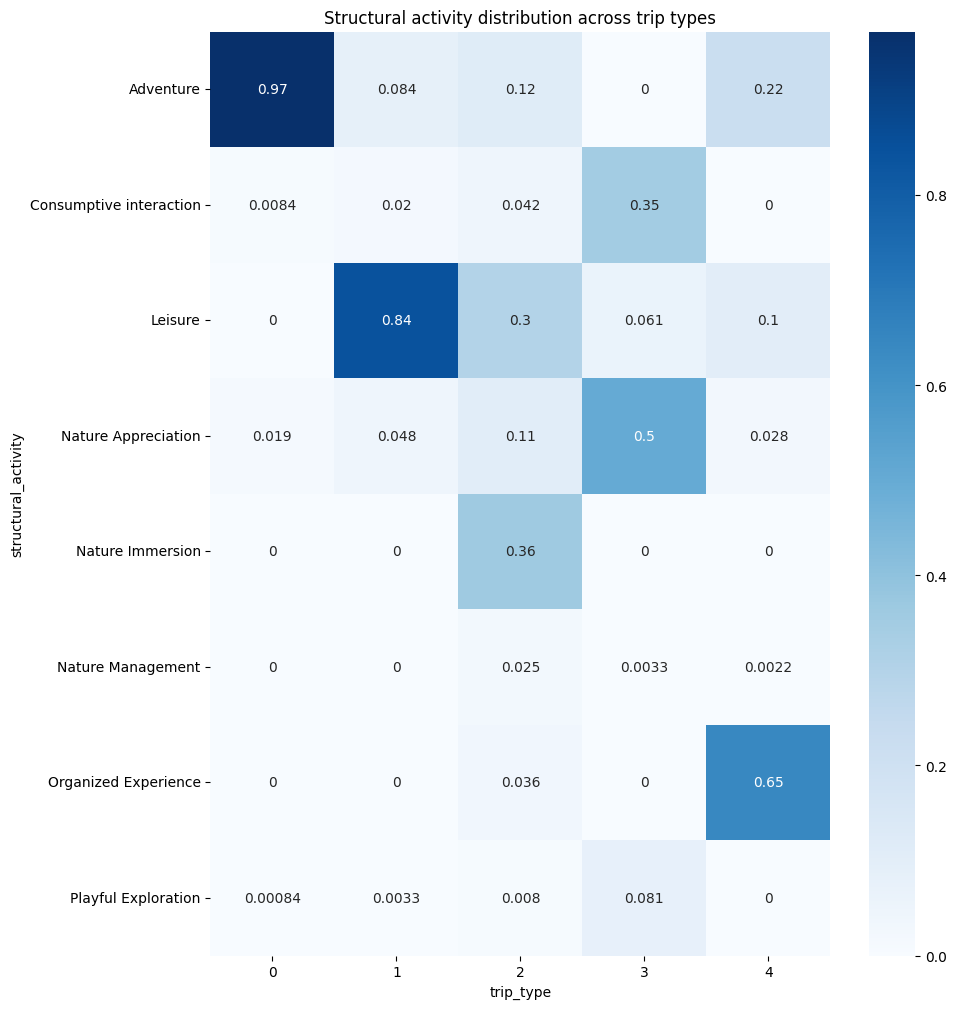

In [56]:
struct_profile = (
    df_all
    .groupby(["trip_type", "structural_activity"])
    .size()
    .reset_index(name="count")
)

struct_profile["share"] = (
    struct_profile
    .groupby("trip_type")["count"]
    .transform(lambda x: x / x.sum())
)

struct_heat = struct_profile.pivot(
    index="structural_activity",
    columns="trip_type",
    values="share"
).fillna(0)

plt.figure(figsize=(10,12))

sns.heatmap(
    struct_heat,
    annot=True,
    cmap="Blues"
)

plt.title("Structural activity distribution across trip types")
plt.show()

In [57]:
activity_dist = (
    df_all
    .groupby(["source", "trip_type", "activity"])
    .size()
    .reset_index(name="count")
)

activity_dist["share"] = (
    activity_dist
    .groupby(["source", "trip_type"])["count"]
    .transform(lambda x: x / x.sum())
)

In [58]:
def plot_heatmap(source_df, source_name, color):
    pivot = source_df.pivot(
        index="activity",
        columns="trip_type",
        values="share"
    ).fillna(0)

    plt.figure(figsize=(8, 10))

    sns.heatmap(
        pivot,
        cmap=color,
        linewidths=0.2
    )

    plt.title(f"{source_name}: Activity composition by trip type")
    plt.xlabel("Trip type")
    plt.ylabel("Activity")

    plt.tight_layout()
    plt.show()

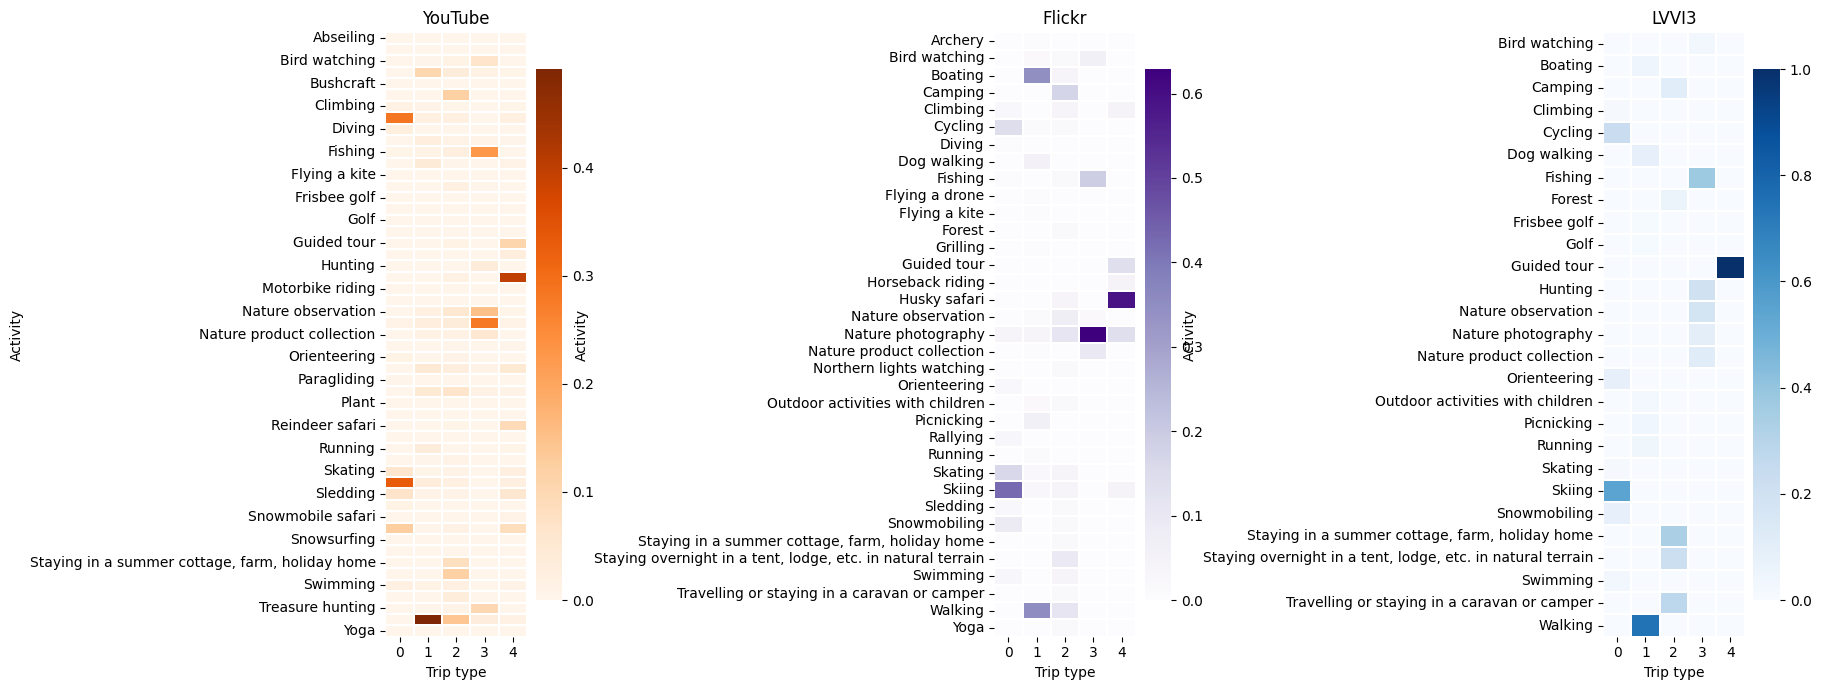

In [59]:
yt = activity_dist[activity_dist["source"] == "YouTube"]
fl = activity_dist[activity_dist["source"] == "Flickr"]
lv = activity_dist[activity_dist["source"] == "LVVI3"]

fig, axes = plt.subplots(1, 3, figsize=(18, 7))

sources = [
    ("YouTube", yt, "Oranges"),
    ("Flickr", fl, "Purples"),
    ("LVVI3", lv, "Blues")
]

for ax, (name, data, cmap) in zip(axes, sources):

    pivot = data.pivot(
        index="activity",
        columns="trip_type",
        values="share"
    ).fillna(0)

    sns.heatmap(
        pivot,
        cmap=cmap,
        ax=ax,
        linewidths=0.2,
        cbar=True
    )

    ax.set_title(name)
    ax.set_xlabel("Trip type")
    ax.set_ylabel("Activity")

plt.tight_layout()
plt.show()

## Trip type count

In [35]:
youtube_trip_demo_cf = youtube_trip_demo[youtube_trip_demo['commercial_forest']==1]
flickr_trip_demo_cf = flickr_trip_demo[flickr_trip_demo['commercial_forest']==1]

# Create a trip-level table
trip_source = pd.concat([
    youtube_trip_demo_cf.assign(source="Flickr"),
    flickr_trip_demo_cf.assign(source="YouTube")
])

In [36]:
# Create a trip-level table
trip_source = pd.concat([
    lvvi3_trip_demo.assign(source="LVVI3"),
    flickr_trip_demo.assign(source="Flickr"),
    youtube_trip_demo.assign(source="YouTube")
])


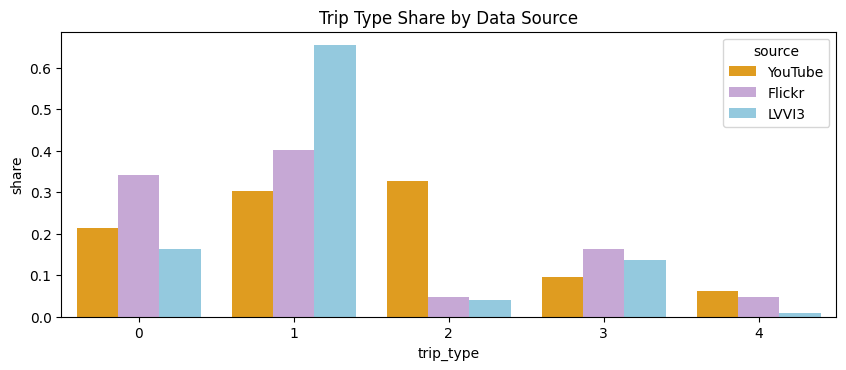

In [42]:
# Compute shares
trip_dist = (
    trip_source
    .groupby(["source", "trip_type"])
    .size()
    .reset_index(name="n")
)

trip_dist["share"] = (
    trip_dist.groupby("source")["n"]
    .transform(lambda x: x/x.sum())
)

palette = {
    "YouTube": "orange",
    "Flickr": "#C9A0DC",
    "LVVI3": "skyblue"
}

custom_order = ["YouTube", "Flickr", "LVVI3"]

plt.figure(figsize=(10, 3.7))

# Plot
sns.barplot(
    data=trip_dist,
    x="trip_type",
    y="share",
    hue="source",
    hue_order=custom_order,
    palette=palette
)

plt.title("Trip Type Share by Data Source")
plt.show()

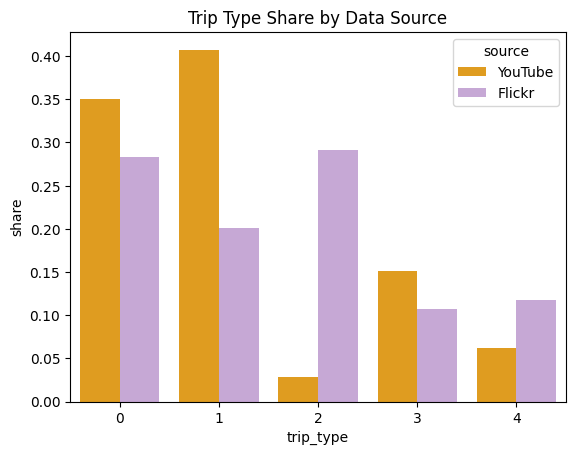

In [42]:
# Compute shares
trip_dist = (
    trip_source
    .groupby(["source", "trip_type"])
    .size()
    .reset_index(name="n")
)

trip_dist["share"] = (
    trip_dist.groupby("source")["n"]
    .transform(lambda x: x/x.sum())
)

palette = {
    "YouTube": "orange",
    "Flickr": "#C9A0DC",
    # "LVVI3": "skyblue"
}

custom_order = ["YouTube", "Flickr"]

# Plot
sns.barplot(
    data=trip_dist,
    x="trip_type",
    y="share",
    hue="source",
    hue_order=custom_order,
    palette=palette
)

plt.title("Trip Type Share by Data Source")
plt.show()

In [ ]:
# How many peopele

In [79]:
def plot_composition(df, column, title, colors):
    fig, axes = plt.subplots(1, 3, figsize=(18, 6), sharey=True)

    sources = ["YouTube", "Flickr", "LVVI3"]

    for ax, src in zip(axes, sources):

        temp = df[df["source"] == src]

        pivot = temp.pivot_table(
            index="trip_type",
            columns=column,
            values="share",
            aggfunc="sum",
            fill_value=0
        )

        pivot.plot(
            kind="bar",
            stacked=True,
            ax=ax,
            color=[colors.get(c, "gray") for c in pivot.columns]
        )

        ax.set_title(src)
        ax.set_xlabel("Trip type")
        ax.set_ylabel("Share")

        ax.legend(
            loc="upper right"
        )

    fig.suptitle(title, fontsize=14)
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

## Social composition distribution

In [76]:
social_dist = (
    df_all
    .groupby(["trip_type", "social_composition", "source"])
    .size()
    .reset_index(name="count")
)

social_dist["share"] = (
    social_dist
    .groupby(["trip_type", "source"])["count"]
    .transform(lambda x: x / x.sum())
)

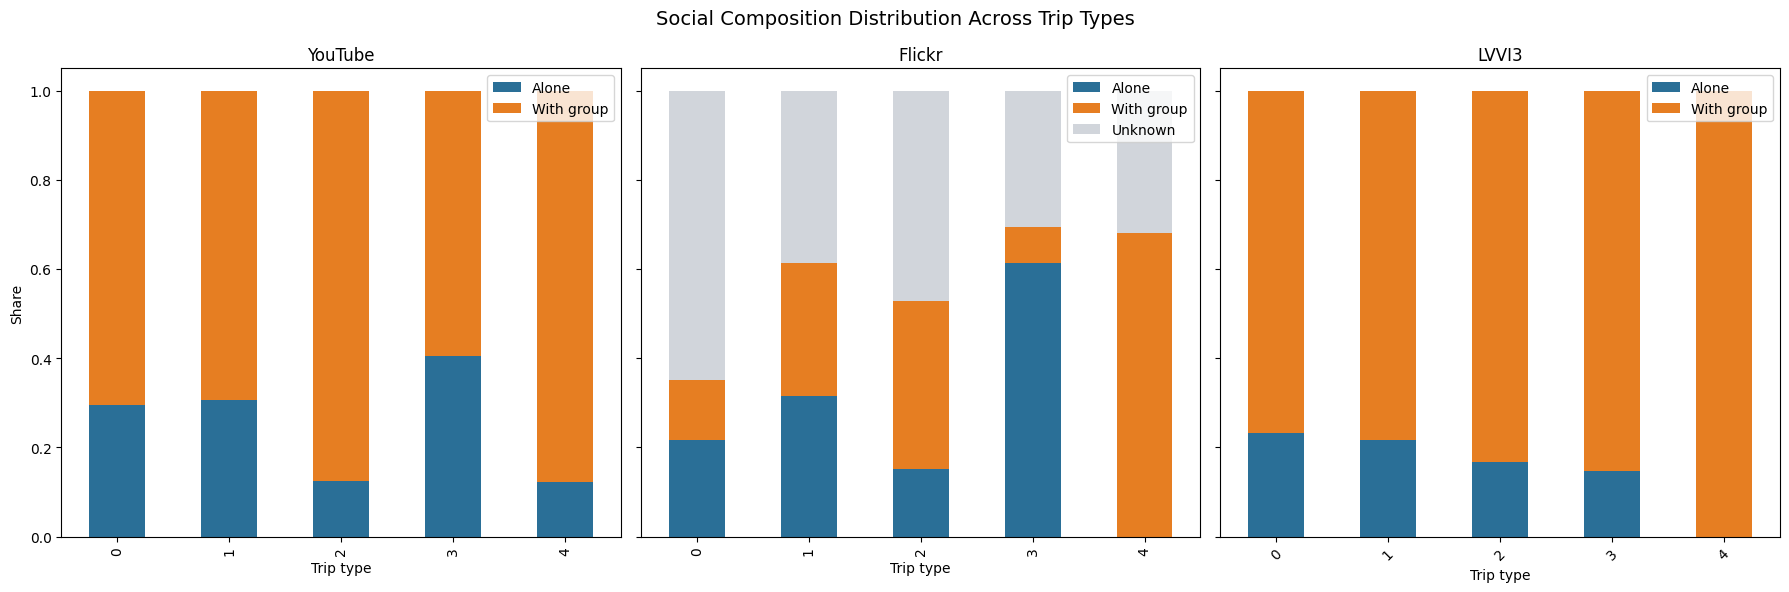

In [80]:
# Define the professional color palette
social_colors = {
    "Alone": "#2A6F97",
    "With group": "#E67E22",
    "Unknown": "#D1D5DB"
}

# Specify order (Unknown last)
social_order = ["Alone", "With group", "Unknown"]

social_dist["social_composition"] = pd.Categorical(
    social_dist["social_composition"],
    categories=social_order,
    ordered=True
)

# Plot
plot_composition(
    social_dist,
    column="social_composition",
    title="Social Composition Distribution Across Trip Types",
    colors=social_colors
)

## Spatial distribution

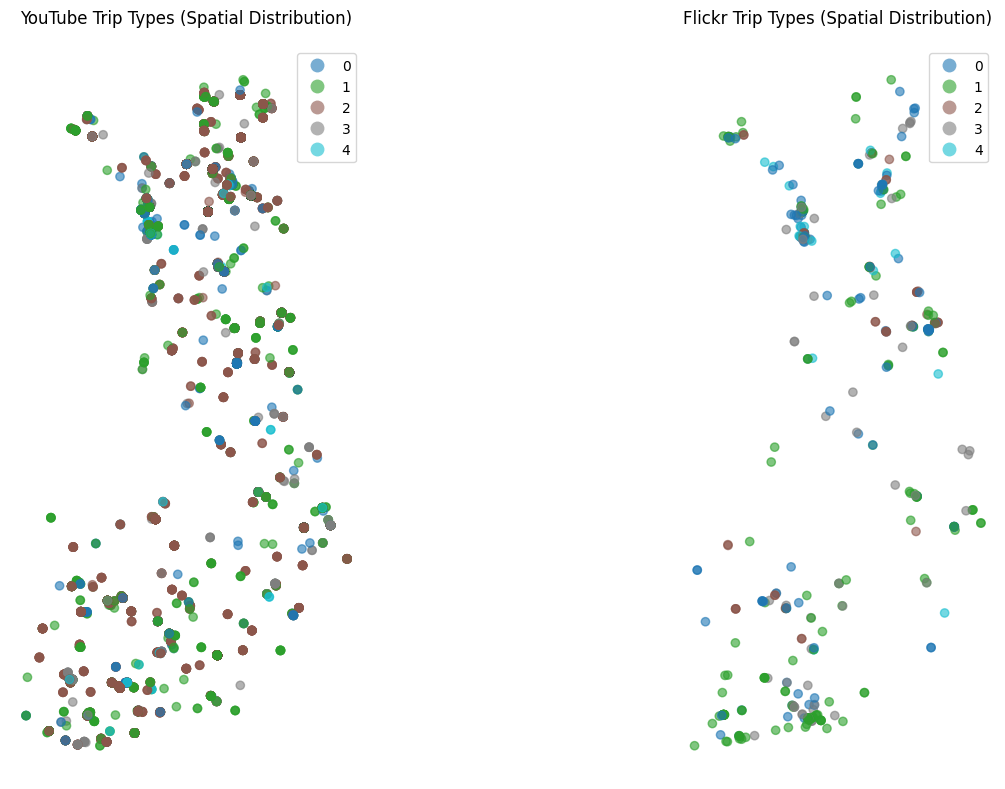

In [102]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(16, 8))

# --- YouTube ---
gdf_youtube_triptypes.plot(
    column="trip_type",
    categorical=True,
    legend=True,
    ax=axes[0],
    alpha=0.6
)
axes[0].set_title("YouTube Trip Types (Spatial Distribution)")
axes[0].axis("off")

# --- Flickr ---
gdf_flickr_triptypes.plot(
    column="trip_type",
    categorical=True,
    legend=True,
    ax=axes[1],
    alpha=0.6
)
axes[1].set_title("Flickr Trip Types (Spatial Distribution)")
axes[1].axis("off")

plt.tight_layout()
plt.show()

/tmp/xuleyi11/34739307/ipykernel_121960/999221698.py:16: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = plt.cm.get_cmap("tab20", len(trip_types))


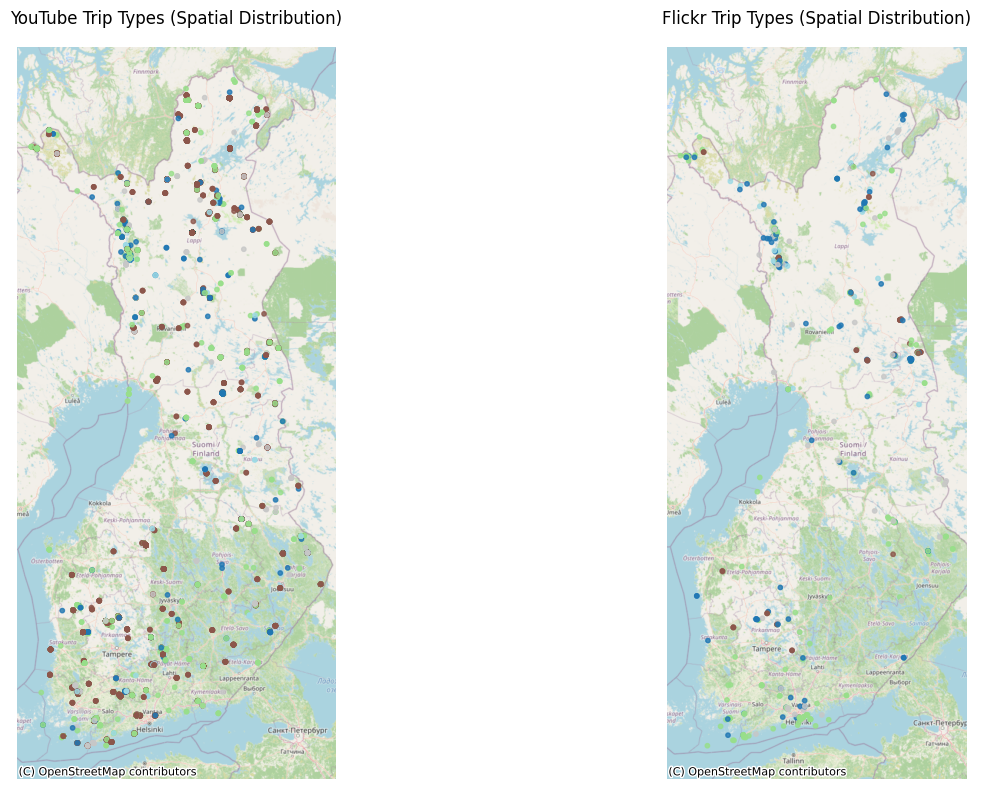

In [24]:
import matplotlib.pyplot as plt
import contextily as ctx

fig, axes = plt.subplots(1, 2, figsize=(16, 8))

# Ensure CRS is Web Mercator (required for basemap)
gdf_youtube_triptypes = gdf_youtube_triptypes.to_crs(epsg=3857)
gdf_flickr_triptypes = gdf_flickr_triptypes.to_crs(epsg=3857)

# --- colormap ---
trip_types = list(
    set(gdf_youtube_triptypes["trip_type"]) |
    set(gdf_flickr_triptypes["trip_type"])
)

cmap = plt.cm.get_cmap("tab20", len(trip_types))
color_map = {t: cmap(i) for i, t in enumerate(trip_types)}

# --- YouTube map ---
gdf_youtube_triptypes.plot(
    ax=axes[0],
    color=gdf_youtube_triptypes["trip_type"].map(color_map),
    alpha=0.8,
    markersize=10
)

ctx.add_basemap(
    axes[0],
    source=ctx.providers.OpenStreetMap.Mapnik
)

axes[0].set_title("YouTube Trip Types (Spatial Distribution)")
axes[0].axis("off")

# --- Flickr map ---
gdf_flickr_triptypes.plot(
    ax=axes[1],
    color=gdf_flickr_triptypes["trip_type"].map(color_map),
    alpha=0.8,
    markersize=10
)

ctx.add_basemap(
    axes[1],
    source=ctx.providers.OpenStreetMap.Mapnik
)

axes[1].set_title("Flickr Trip Types (Spatial Distribution)")
axes[1].axis("off")

plt.tight_layout()
plt.show()

## Temporal distribution

### Heatmap

In [83]:
yt_trips = (
    gdf_youtube_triptypes
    .drop_duplicates(subset=["video_id"])
    [["video_id", "month", "trip_type"]]
)

yt_monthly = (
    yt_trips
    .groupby(["month", "trip_type"])
    .size()
    .reset_index(name="count")
)

yt_monthly["share"] = (
    yt_monthly
    .groupby("month")["count"]
    .transform(lambda x: x / x.sum())
)

In [91]:
gdf_flickr_triptypes["month"] = (
    pd.to_datetime(gdf_flickr_triptypes["trip_start"])
    .dt.month
)

flickr_trips = (
    gdf_flickr_triptypes
    .drop_duplicates(subset=["trip_id"])
    [["trip_id", "month", "trip_type"]]
)

flickr_monthly = (
    flickr_trips
    .groupby(["month", "trip_type"])
    .size()
    .reset_index(name="count")
)

flickr_monthly["share"] = (
    flickr_monthly
    .groupby("month")["count"]
    .transform(lambda x: x / x.sum())
)

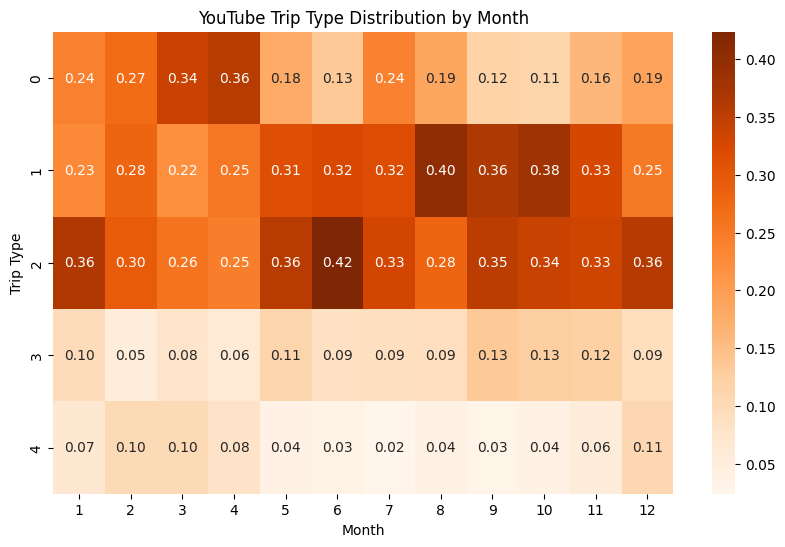

In [86]:
import seaborn as sns
import matplotlib.pyplot as plt

yt_heat = yt_monthly.pivot(
    index="trip_type",
    columns="month",
    values="share"
).fillna(0)

plt.figure(figsize=(10,6))

sns.heatmap(
    yt_heat,
    cmap="Oranges",
    annot=True,
    fmt=".2f"
)

plt.title("YouTube Trip Type Distribution by Month")
plt.xlabel("Month")
plt.ylabel("Trip Type")

plt.show()

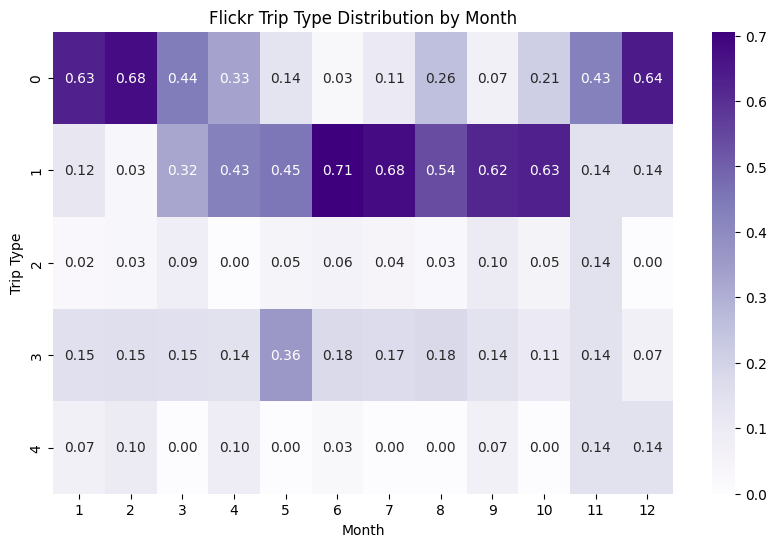

In [ ]:
flickr_heat = flickr_monthly.pivot(
    index="trip_type",
    columns="month",
    values="share"
).fillna(0)

plt.figure(figsize=(10,6))

sns.heatmap(
    flickr_heat,
    cmap="Purples",
    annot=True,
    fmt=".2f"
)

plt.title("Flickr Trip Type Distribution by Month")
plt.xlabel("Month")
plt.ylabel("Trip Type")

plt.show()

### Lineplot

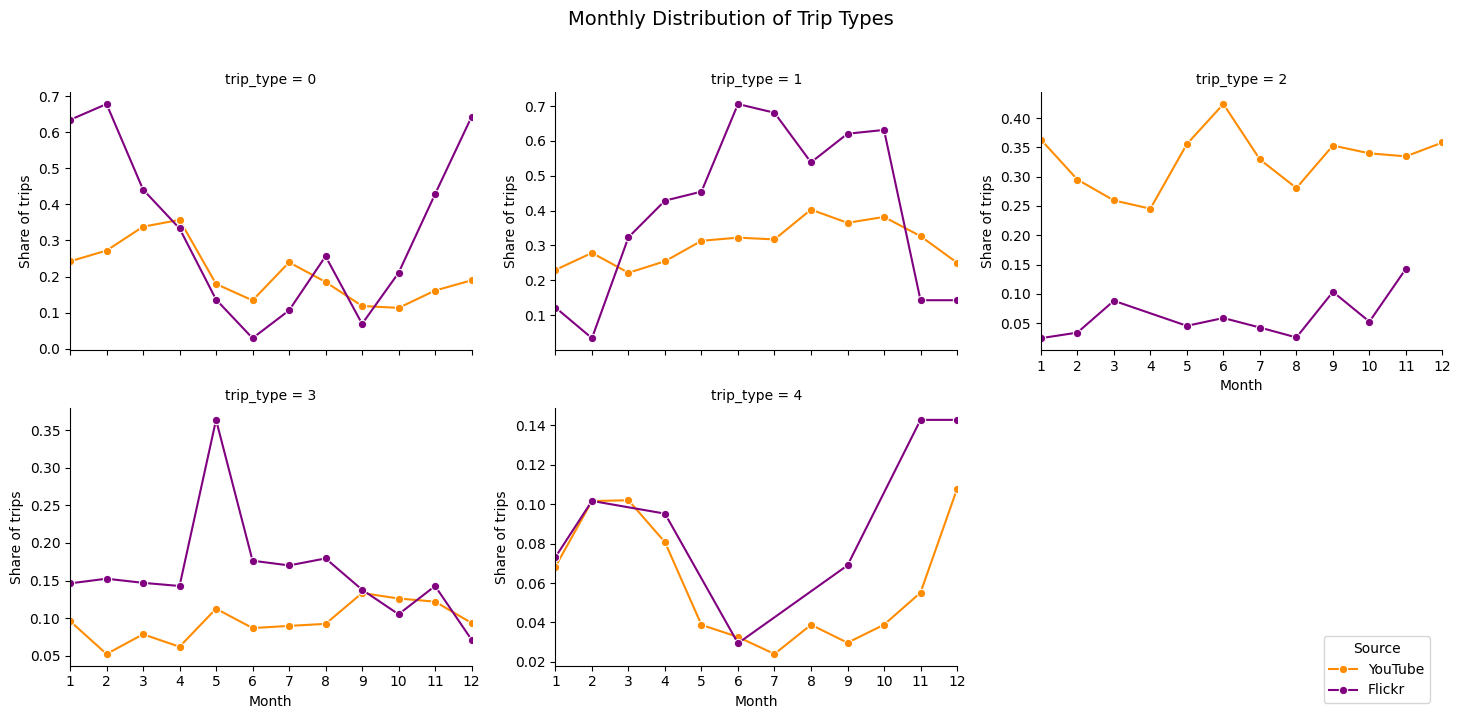

In [101]:
import seaborn as sns
import matplotlib.pyplot as plt

# Combine datasets
yt_monthly["source"] = "YouTube"
flickr_monthly["source"] = "Flickr"

monthly = pd.concat(
    [yt_monthly, flickr_monthly],
    ignore_index=True
)

# Ensure month is integer
monthly["month"] = monthly["month"].astype(int)

palette = {
    "YouTube": "darkorange",
    "Flickr": "purple"
}

g = sns.FacetGrid(
    monthly,
    col="trip_type",
    hue="source",
    col_wrap=3,
    height=3.5,
    aspect=1.3,
    sharey=False,
    palette=palette
)

g.map_dataframe(
    sns.lineplot,
    x="month",
    y="share",
    marker="o"
)

# Force integer month ticks
for ax in g.axes.flat:
    ax.set_xticks(range(1, 13))
    ax.set_xlim(1, 12)
    ax.set_xlabel("Month")
    ax.set_ylabel("Share of trips")

g.add_legend()
sns.move_legend(
    g,
    "lower right",
    bbox_to_anchor=(0.98, 0.02),
    frameon=True,
    title="Source"
)

g.fig.suptitle(
    "Monthly Distribution of Trip Types",
    y=1.02,
    fontsize=14
)

plt.tight_layout()
plt.show()

# Statistical analysis

## Multinomial logistic regression